# Exploratory Data Analysis

## Dataset Overview

The shape and structure of the dataset: rows, columns, types, missing values and what the values look like.

### O1. Setup and load

VS Code runs the notebook from `notebooks/`, so the data path is `../data/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)

DATA = Path("../data/Flight_Data_With_Weather_Final.csv")
df = pd.read_csv(DATA, low_memory=False, parse_dates=["FL_DATE"])

### O2. Shape

In [2]:
print(f"rows:    {df.shape[0]:,}")
print(f"columns: {df.shape[1]}")
print(f"memory:  {df.memory_usage(deep=True).sum() / 1e6:,.1f} MB")
print(f"dates:   {df['FL_DATE'].min().date()} to {df['FL_DATE'].max().date()}")

rows:    148,273
columns: 123


memory:  254.7 MB
dates:   2023-01-01 to 2025-07-31


### O3. Column summary

One row per column: its group, type, how much is missing, how many distinct values, and an example value.

In [3]:
WEATHER_PREFIXES = {"temp", "prcp", "wspd", "wpgt", "pres", "snow", "coco"}
DELAY_CAUSES = {"CARRIER_DELAY", "WEATHER_DELAY", "NAS_DELAY", "SECURITY_DELAY", "LATE_AIRCRAFT_DELAY"}

def column_group(col: str) -> str:
    if col.split("_")[0] in WEATHER_PREFIXES:
        return "weather (origin)" if col.endswith("_ORIGIN") else "weather (dest)"
    if col.startswith("DIV"):
        return "diversion details"
    if col in DELAY_CAUSES:
        return "delay causes"
    if col in {"YEAR", "QUARTER", "MONTH", "DAY_OF_MONTH", "DAY_OF_WEEK", "FL_DATE"}:
        return "date"
    if col.startswith("OP_") or col == "TAIL_NUM":
        return "carrier"
    if col.startswith("ORIGIN"):
        return "origin"
    if col.startswith("DEST"):
        return "destination"
    if col in {"CRS_DEP_TIME", "TAXI_OUT", "WHEELS_OFF"} or col.startswith("DEP_"):
        return "departure"
    if col in {"CRS_ARR_TIME", "TAXI_IN", "WHEELS_ON"} or col.startswith("ARR_"):
        return "arrival"
    if col in {"CANCELLED", "CANCELLATION_CODE", "DIVERTED"}:
        return "cancellation / diversion"
    if col in {"FIRST_DEP_TIME", "TOTAL_ADD_GTIME", "LONGEST_ADD_GTIME"}:
        return "gate return"
    return "flight summary"

columns = pd.DataFrame({
    "group": [column_group(c) for c in df.columns],
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(1),
    "n_unique": df.nunique(),
    "example": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns],
})
columns

,group,dtype,non_null,pct_missing,n_unique,example
YEAR,date,int64,148273,0.0,3,2023
QUARTER,date,int64,148273,0.0,4,1
MONTH,date,int64,148273,0.0,12,1
DAY_OF_MONTH,date,int64,148273,0.0,31,16
DAY_OF_WEEK,date,int64,148273,0.0,7,1
FL_DATE,date,datetime64[us],148273,0.0,943,2023-01-16 00:00:00
OP_UNIQUE_CARRIER,carrier,str,148273,0.0,15,9E
OP_CARRIER_AIRLINE_ID,carrier,int64,148273,0.0,15,20363
OP_CARRIER,carrier,str,148273,0.0,15,9E
TAIL_NUM,carrier,str,147952,0.2,6308,N306PQ


### O4. Column groups

How many columns each group has, and how many of them are mostly empty (over 90% missing).

In [4]:
groups = columns.groupby("group").agg(
    n_columns=("dtype", "size"),
    mostly_empty=("pct_missing", lambda s: (s > 90).sum()),
    avg_pct_missing=("pct_missing", "mean"),
).round(1).sort_values("n_columns", ascending=False)
groups

,n_columns,mostly_empty,avg_pct_missing
group,,,
diversion details,46,44,95.6
origin,9,0,0.0
destination,9,0,0.0
departure,9,0,1.0
arrival,9,0,1.1
weather (origin),7,0,0.0
weather (dest),7,0,0.0
flight summary,6,0,0.5
date,6,0,0.0


### O5. Sample rows

The first five rows, transposed so all columns are readable.

In [5]:
df.head().T

,0,1,2,3,4
YEAR,2023,2023,2023,2023,2023
QUARTER,1,1,1,1,1
MONTH,1,1,1,1,1
DAY_OF_MONTH,16,30,30,16,2
DAY_OF_WEEK,1,1,1,1,1
FL_DATE,2023-01-16 00:00:00,2023-01-30 00:00:00,2023-01-30 00:00:00,2023-01-16 00:00:00,2023-01-02 00:00:00
OP_UNIQUE_CARRIER,9E,9E,9E,9E,9E
OP_CARRIER_AIRLINE_ID,20363,20363,20363,20363,20363
OP_CARRIER,9E,9E,9E,9E,9E
TAIL_NUM,N306PQ,N923XJ,N8918B,N296PQ,N368CA


### O6. Numeric summary

In [6]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
YEAR,148273.0,2023.852832,2023.0,2023.0,2024.0,2024.0,2025.0,0.765111
QUARTER,148273.0,2.354232,1.0,1.0,2.0,3.0,4.0,1.079542
MONTH,148273.0,6.031921,1.0,3.0,6.0,9.0,12.0,3.301618
DAY_OF_MONTH,148273.0,15.459915,1.0,8.0,15.0,24.0,31.0,9.010895
DAY_OF_WEEK,148273.0,3.982202,1.0,2.0,4.0,6.0,7.0,2.005614
FL_DATE,148273,2024-04-23 11:52:14.124216,2023-01-01 00:00:00,2023-09-01 00:00:00,2024-04-29 00:00:00,2024-12-12 00:00:00,2025-07-31 00:00:00,NaN
OP_CARRIER_AIRLINE_ID,148273.0,19901.659142,19393.0,19790.0,19805.0,20304.0,20452.0,368.81817
OP_CARRIER_FL_NUM,148273.0,2314.830778,1.0,1087.0,2070.0,3325.0,8816.0,1554.436067
ORIGIN_AIRPORT_ID,148273.0,12641.213329,10140.0,11292.0,12889.0,13930.0,15919.0,1512.083023
ORIGIN_AIRPORT_SEQ_ID,148273.0,1264125.374768,1014005.0,1129202.0,1288904.0,1393008.0,1591905.0,151208.122097


### O7. Categorical summary

Text columns: number of distinct values and the five most common.

In [7]:
text_cols = df.select_dtypes(include=["object", "string"]).columns

pd.DataFrame({
    "n_unique": [df[c].nunique() for c in text_cols],
    "top_5": [df[c].value_counts().head(5).to_dict() for c in text_cols],
}, index=text_cols)

,n_unique,top_5
OP_UNIQUE_CARRIER,15,"{'WN': 35006, 'DL': 22643, 'AA': 22457, 'UA': ..."
OP_CARRIER,15,"{'WN': 35006, 'DL': 22643, 'AA': 22457, 'UA': ..."
TAIL_NUM,6308,"{'N486HA': 117, 'N478HA': 108, 'N489HA': 107, ..."
ORIGIN,136,"{'ATL': 8415, 'DFW': 7736, 'DEN': 7687, 'ORD':..."
ORIGIN_CITY_NAME,131,"{'Chicago, IL': 9064, 'Atlanta, GA': 8415, 'Da..."
ORIGIN_STATE_ABR,43,"{'TX': 17161, 'CA': 16511, 'FL': 14290, 'IL': ..."
ORIGIN_STATE_NM,43,"{'Texas': 17161, 'California': 16511, 'Florida..."
DEST,350,"{'ATL': 5429, 'DEN': 5408, 'ORD': 4634, 'LAX':..."
DEST_CITY_NAME,344,"{'Chicago, IL': 6639, 'Atlanta, GA': 5429, 'De..."
DEST_STATE_ABR,52,"{'CA': 17540, 'TX': 14506, 'FL': 13894, 'NY': ..."


## A. Coverage and Scope

How much of the dataset is ATL/DFW, and how dense the data is per day and per hour.
These answers decide what we can predict (e.g. an hourly arrival rate) and whether the pipeline can be tested on airports beyond ATL/DFW.

In [8]:
HUBS = ["ATL", "DFW"]

### A1. All airports

Flights by origin and destination. How many airports have enough rows to test the "any ICAO code" requirement beyond ATL/DFW?

In [9]:
airports = pd.DataFrame({
    "as_origin": df["ORIGIN"].value_counts(),
    "as_dest": df["DEST"].value_counts(),
}).fillna(0).astype(int)
airports["total"] = airports["as_origin"] + airports["as_dest"]
airports = airports.sort_values("total", ascending=False)

print(f"{len(airports)} airports in the dataset")
for n in [1_000, 2_000, 5_000]:
    print(f"airports with >= {n:,} rows: {(airports['total'] >= n).sum()}")
airports.head(15)

350 airports in the dataset
airports with >= 1,000 rows: 57
airports with >= 2,000 rows: 43
airports with >= 5,000 rows: 20


,as_origin,as_dest,total
ATL,8415,5429,13844
DEN,7687,5408,13095
DFW,7736,4032,11768
ORD,7103,4634,11737
LAX,4832,4443,9275
PHX,4798,4015,8813
LAS,4834,3964,8798
CLT,5147,3270,8417
MCO,4057,3581,7638
LGA,3976,3017,6993


### A2. ATL/DFW subset

Departures and arrivals per hub, direct ATL to DFW flights, and the hubs' share of the dataset.

In [10]:
hub_summary = pd.DataFrame({
    "departures": [(df["ORIGIN"] == h).sum() for h in HUBS],
    "arrivals": [(df["DEST"] == h).sum() for h in HUBS],
}, index=HUBS)
hub_summary["total"] = hub_summary.sum(axis=1)

touches_hub = df["ORIGIN"].isin(HUBS) | df["DEST"].isin(HUBS)
between_hubs = df["ORIGIN"].isin(HUBS) & df["DEST"].isin(HUBS)

print(f"rows touching ATL or DFW: {touches_hub.sum():,} ({touches_hub.mean():.1%} of dataset)")
print(f"rows between ATL and DFW: {between_hubs.sum():,}")
hub_summary

rows touching ATL or DFW: 25,299 (17.1% of dataset)
rows between ATL and DFW: 313


,departures,arrivals,total
ATL,8415,5429,13844
DFW,7736,4032,11768


### A3. Daily volume per hub

Departures and arrivals per day (7-day rolling mean on the chart), summary stats, and days with no flights.

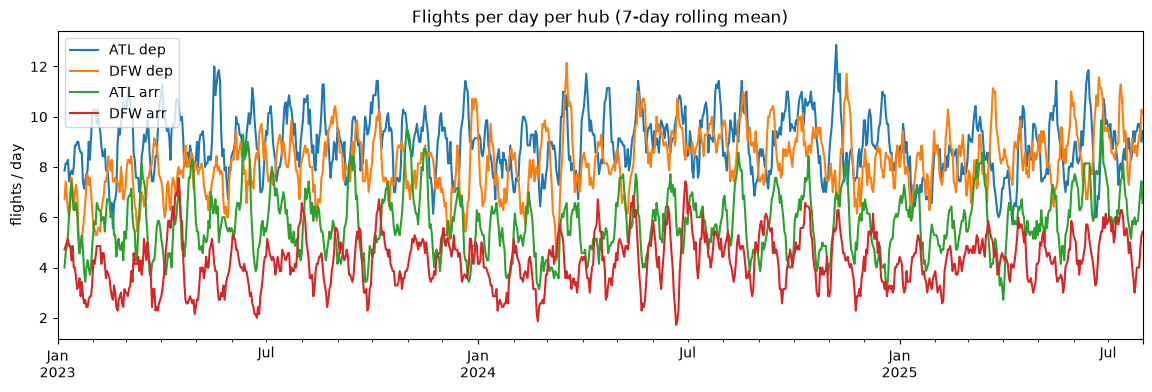

days with zero flights:
ATL dep     0
DFW dep     0
ATL arr     4
DFW arr    17
dtype: int64


,ATL dep,DFW dep,ATL arr,DFW arr
count,943.0,943.0,943.0,943.0
mean,8.9,8.2,5.8,4.3
std,2.7,2.6,2.6,2.2
min,1.0,1.0,0.0,0.0
25%,7.0,6.0,4.0,3.0
50%,9.0,8.0,5.0,4.0
75%,11.0,10.0,7.0,6.0
max,19.0,16.0,18.0,14.0


In [11]:
all_dates = pd.date_range(df["FL_DATE"].min(), df["FL_DATE"].max(), freq="D")

daily = pd.DataFrame({
    **{f"{h} dep": df[df["ORIGIN"] == h].groupby("FL_DATE").size() for h in HUBS},
    **{f"{h} arr": df[df["DEST"] == h].groupby("FL_DATE").size() for h in HUBS},
}).reindex(all_dates).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(14, 4))
daily.rolling(7).mean().plot(ax=ax)
ax.set_title("Flights per day per hub (7-day rolling mean)")
ax.set_ylabel("flights / day")
plt.show()

print("days with zero flights:")
print((daily == 0).sum())
daily.describe().round(1)

### A4. Hourly profile per hub

Flights by scheduled hour, and how many flights fall in each airport-hour (including empty hours).
This shows how sparse an hourly arrival count would be as a target.

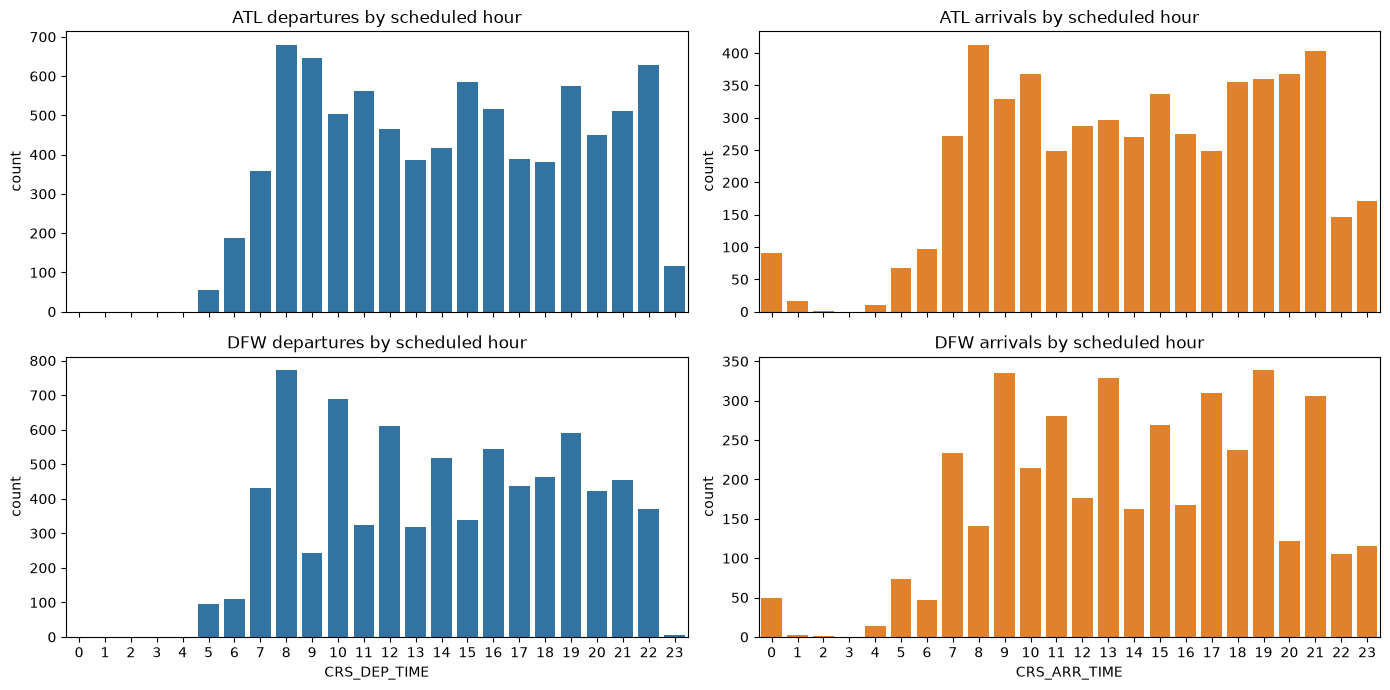

In [12]:
def sched_hour(hhmm: pd.Series) -> pd.Series:
    """HHMM integer -> hour 0-23 (2400 becomes 0)."""
    return (hhmm // 100).astype(int) % 24

fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
for i, h in enumerate(HUBS):
    dep_hours = sched_hour(df.loc[df["ORIGIN"] == h, "CRS_DEP_TIME"])
    arr_hours = sched_hour(df.loc[df["DEST"] == h, "CRS_ARR_TIME"])
    sns.countplot(x=dep_hours, order=range(24), ax=axes[i, 0], color="C0")
    sns.countplot(x=arr_hours, order=range(24), ax=axes[i, 1], color="C1")
    axes[i, 0].set_title(f"{h} departures by scheduled hour")
    axes[i, 1].set_title(f"{h} arrivals by scheduled hour")
plt.tight_layout()
plt.show()

In [13]:
# Flights per airport-hour, counting hours with zero flights
full_index = pd.MultiIndex.from_product([all_dates, range(24)], names=["date", "hour"])

per_hour = {}
for h in HUBS:
    for kind, col, time_col in [("dep", "ORIGIN", "CRS_DEP_TIME"), ("arr", "DEST", "CRS_ARR_TIME")]:
        sub = df[df[col] == h]
        counts = sub.groupby([sub["FL_DATE"], sched_hour(sub[time_col])]).size()
        counts.index.names = ["date", "hour"]
        per_hour[f"{h} {kind}"] = counts.reindex(full_index, fill_value=0)

per_hour = pd.DataFrame(per_hour)
print("share of airport-hours with N flights:")
per_hour.apply(lambda s: s.value_counts(normalize=True)).sort_index().round(3)

share of airport-hours with N flights:


,ATL dep,ATL arr,DFW dep,DFW arr
0,0.711,0.795,0.735,0.844
1,0.219,0.175,0.201,0.136
2,0.058,0.027,0.052,0.019
3,0.010,0.003,0.010,0.001
4,0.001,0.000,0.001,0.000
5,0.000,0.000,0.000,NaN
6,NaN,NaN,0.000,NaN


### A5. Date coverage

Rows per month for each hub, and dates in the range with no hub flights at all.

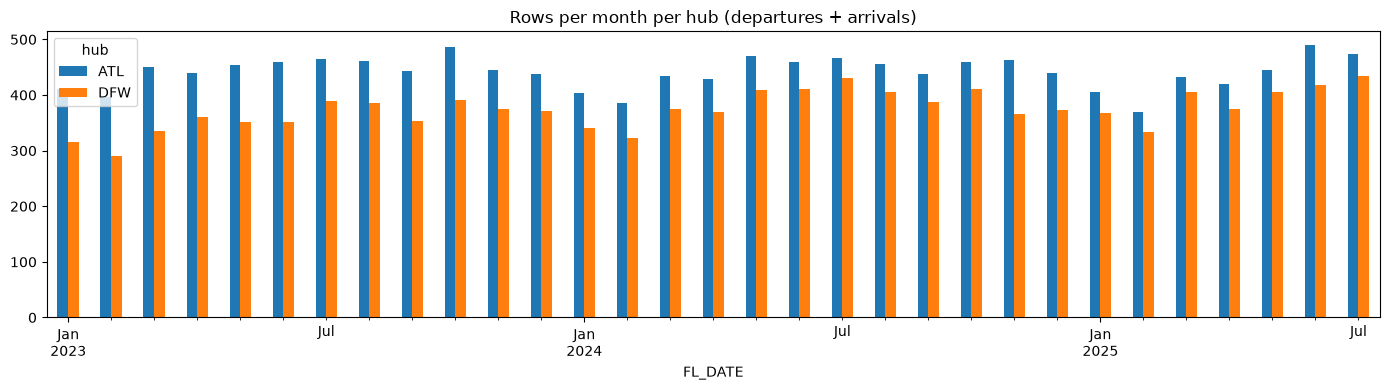

date range: 2023-01-01 to 2025-07-31 (943 days)
dates with no ATL/DFW flights: 0


In [14]:
hub_rows = df[touches_hub].copy()
hub_rows["hub"] = np.where(hub_rows["ORIGIN"].isin(HUBS), hub_rows["ORIGIN"], hub_rows["DEST"])
monthly = hub_rows.groupby([hub_rows["FL_DATE"].dt.to_period("M"), "hub"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(14, 4))
monthly.plot(kind="bar", ax=ax)
ax.set_title("Rows per month per hub (departures + arrivals)")
plt.tight_layout()
plt.show()

missing_dates = all_dates.difference(hub_rows["FL_DATE"].unique())
print(f"date range: {all_dates.min().date()} to {all_dates.max().date()} ({len(all_dates)} days)")
print(f"dates with no ATL/DFW flights: {len(missing_dates)}")

### A6. Carrier mix at the hubs

Which airlines appear in the ATL and DFW subsets.

In [15]:
carriers = pd.crosstab(hub_rows["OP_UNIQUE_CARRIER"], hub_rows["hub"])
carriers["total"] = carriers.sum(axis=1)
carriers.sort_values("total", ascending=False)

hub,ATL,DFW,total
OP_UNIQUE_CARRIER,,,
DL,9245,493,9738
AA,360,6983,7343
MQ,14,1774,1788
WN,1587,0,1587
OO,299,787,1086
NK,582,423,1005
UA,412,457,869
F9,470,372,842
9E,481,0,481


## B. Weather Join

How the weather columns were attached to each flight: which hour they match, what units they use, and how clean they are.
This decides whether we can rebuild one weather timeline per airport (Section C) and use past weather to predict delays (Section E).

In [16]:
WX = ["temp", "prcp", "wspd", "wpgt", "pres", "snow", "coco"]
WX_ORIGIN = [f"{w}_ORIGIN" for w in WX]
WX_DEST = [f"{w}_DEST" for w in WX]

def hour_of(hhmm: pd.Series) -> pd.Series:
    """HHMM number -> hour 0-23 (2400 becomes 0). Drop NaNs before calling."""
    return (hhmm // 100).astype(int) % 24

def consistency(data: pd.DataFrame, keys: list, wx_cols: list) -> tuple[float, int]:
    """Share of groups (with 2+ flights) whose weather is identical across all flights in the group."""
    sizes = data.groupby(keys).size()
    multi = sizes[sizes >= 2].index
    n_unique = data.groupby(keys)[wx_cols].nunique().loc[multi]
    return (n_unique.max(axis=1) == 1).mean(), len(multi)

### B1. Which hour is origin weather matched to?

Group departures by date + airport + hour. If every flight in a group has identical weather, that grouping is probably how the weather was joined.
We compare the scheduled departure hour, the actual departure hour, and the departure time block. All airports are used for a larger sample.

In [17]:
dep = df.copy()
dep["sched_hour"] = hour_of(dep["CRS_DEP_TIME"])
flown = dep[dep["DEP_TIME"].notna()].copy()
flown["actual_hour"] = hour_of(flown["DEP_TIME"])

results = {
    "scheduled hour (CRS_DEP_TIME)": consistency(dep, ["FL_DATE", "ORIGIN", "sched_hour"], WX_ORIGIN),
    "actual hour (DEP_TIME)": consistency(flown, ["FL_DATE", "ORIGIN", "actual_hour"], WX_ORIGIN),
    "time block (DEP_TIME_BLK)": consistency(dep, ["FL_DATE", "ORIGIN", "DEP_TIME_BLK"], WX_ORIGIN),
}
pd.DataFrame(results, index=["share_identical", "groups_tested"]).T

,share_identical,groups_tested
scheduled hour (CRS_DEP_TIME),1.000000,14221.0
actual hour (DEP_TIME),0.641035,13330.0
time block (DEP_TIME_BLK),0.997755,14251.0


In [18]:
# Cancelled flights have no actual departure time. Do they still have weather?
cancelled = df[df["CANCELLED"] == 1]
print(f"cancelled flights: {len(cancelled):,}")
print(f"cancelled flights with origin weather present: {cancelled[WX_ORIGIN].notna().all(axis=1).mean():.1%}")

cancelled flights: 1,901
cancelled flights with origin weather present: 100.0%


### B2. Which hour is destination weather matched to?

The same test for arrivals: scheduled vs actual arrival hour.
Note: `FL_DATE` is the departure date, so overnight flights land on the next day. This adds a little noise.

Then a cross-check: does an airport's weather at a given date and hour match whether it appears as an *origin* or a *destination*?
If yes, both columns come from one weather series per airport.

In [19]:
arr = df.copy()
arr["sched_hour"] = hour_of(arr["CRS_ARR_TIME"])
landed = arr[arr["ARR_TIME"].notna()].copy()
landed["actual_hour"] = hour_of(landed["ARR_TIME"])

results = {
    "scheduled hour (CRS_ARR_TIME)": consistency(arr, ["FL_DATE", "DEST", "sched_hour"], WX_DEST),
    "actual hour (ARR_TIME)": consistency(landed, ["FL_DATE", "DEST", "actual_hour"], WX_DEST),
    "time block (ARR_TIME_BLK)": consistency(arr, ["FL_DATE", "DEST", "ARR_TIME_BLK"], WX_DEST),
}
pd.DataFrame(results, index=["share_identical", "groups_tested"]).T

,share_identical,groups_tested
scheduled hour (CRS_ARR_TIME),1.000000,8969.0
actual hour (ARR_TIME),0.547608,8318.0
time block (ARR_TIME_BLK),0.987775,9080.0


In [20]:
# Cross-check: same airport, date and hour, seen as origin vs as destination
def first_wx(data, airport_col, hour_col, wx_cols):
    out = data.groupby(["FL_DATE", airport_col, hour_col])[wx_cols].first()
    out.index.names = ["date", "airport", "hour"]
    out.columns = WX
    return out

for label, o_data, a_data, hour_col in [
    ("scheduled", dep, arr, "sched_hour"),
    ("actual", flown, landed, "actual_hour"),
]:
    o = first_wx(o_data, "ORIGIN", hour_col, WX_ORIGIN)
    d = first_wx(a_data, "DEST", hour_col, WX_DEST)
    both = o.join(d, how="inner", suffixes=("_o", "_d"))
    match = pd.concat([(both[f"{w}_o"] == both[f"{w}_d"]) for w in WX], axis=1).all(axis=1)
    print(f"{label} hours: {len(both):,} airport-hours seen both ways, weather identical in {match.mean():.1%}")

scheduled hours: 18,112 airport-hours seen both ways, weather identical in 99.9%
actual hours: 17,582 airport-hours seen both ways, weather identical in 56.8%


### B3. Units and ranges

The column names match Meteostat's format, which uses °C (temp), mm (prcp), km/h (wspd, wpgt) and hPa (pres).
Check that ATL and DFW values fit those units. One row per airport-date-hour, so busy hours are not counted twice.

In [21]:
HUBS = ["ATL", "DFW"]  # defined again so this section runs on its own

o = dep[dep["ORIGIN"].isin(HUBS)][["FL_DATE", "ORIGIN", "sched_hour"] + WX_ORIGIN]
o.columns = ["date", "airport", "hour"] + WX
d = arr[arr["DEST"].isin(HUBS)][["FL_DATE", "DEST", "sched_hour"] + WX_DEST]
d.columns = ["date", "airport", "hour"] + WX
hub_wx = pd.concat([o, d]).drop_duplicates(["date", "airport", "hour"])

print(f"{len(hub_wx):,} airport-date-hours with weather at ATL/DFW")
hub_wx.groupby("airport")[WX].describe().T.round(1)

17,721 airport-date-hours with weather at ATL/DFW


airport        ATL     DFW
temp count  9411.0  8310.0
     mean     18.8    20.3
     std       8.6     9.7
     min     -10.0   -11.7
     25%      12.8    13.3
     50%      20.0    21.7
     75%      25.0    27.2
     max      37.2    42.8
prcp count  9411.0  8310.0
     mean      0.1     0.1
     std       0.9     1.0
     min       0.0     0.0
     25%       0.0     0.0
     50%       0.0     0.0
     75%       0.0     0.0
     max      20.8    33.0
wspd count  9411.0  8310.0
     mean     13.4    16.6
     std       7.4     8.9
     min       0.0     0.0
     25%       9.4    11.0
     50%      13.0    14.8
     75%      16.6    22.3
     max      57.6    57.6
wpgt count  9411.0  8310.0
     mean      0.3     0.7
     std       2.6     3.9
     min       0.0     0.0
     25%       0.0     0.0
     50%       0.0     0.0
     75%       0.0     0.0
     max      46.0    42.0
pres count  9411.0  8310.0
     mean   1017.5  1015.2
     std       5.6     6.5
     min     985.3   992.8
     25%    1013.9  1011.0
     50%    1017.3  1014.5
     75%    1020.7  1018.5
     max    1038.5  1041.6
snow count  9411.0  8310.0
     mean      0.0     0.0
     std       0.0     0.0
     min       0.0     0.0
     25%       0.0     0.0
     50%       0.0     0.0
     75%       0.0     0.0
     max       0.0     0.0
coco count  9411.0  8310.0
     mean      3.3     3.3
     std       2.8     2.6
     min       0.0     0.0
     25%       2.0     2.0
     50%       3.0     3.0
     75%       4.0     4.0
     max      25.0    25.0

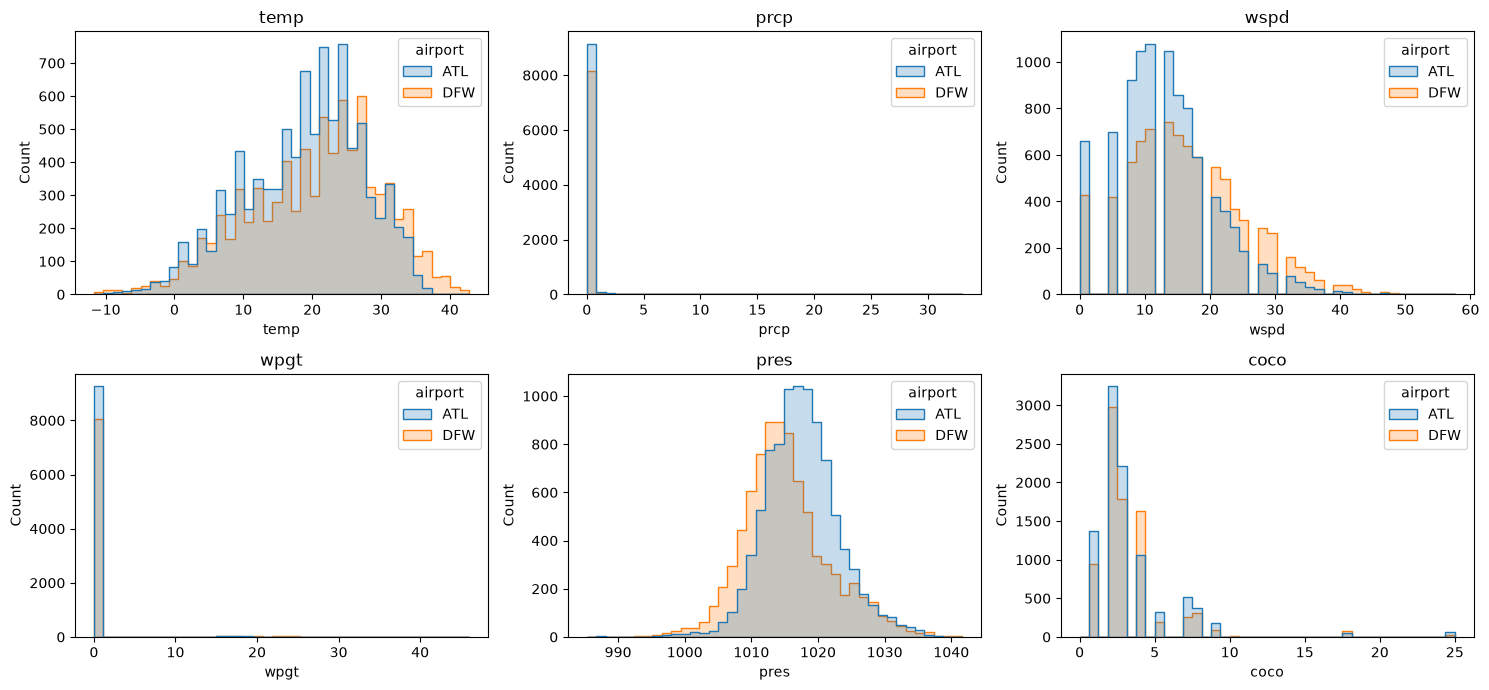

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, w in zip(axes.flat, ["temp", "prcp", "wspd", "wpgt", "pres", "coco"]):
    sns.histplot(data=hub_wx, x=w, hue="airport", bins=40, element="step", ax=ax)
    ax.set_title(w)
plt.tight_layout()
plt.show()

### B4. Weather condition codes (`coco`)

Frequency of each code at ATL/DFW. **Assumption:** labels follow Meteostat's code list, based on the matching column names.

In [23]:
COCO_LABELS = {
    1: "clear", 2: "fair", 3: "cloudy", 4: "overcast", 5: "fog", 6: "freezing fog",
    7: "light rain", 8: "rain", 9: "heavy rain", 10: "freezing rain", 11: "heavy freezing rain",
    12: "sleet", 13: "heavy sleet", 14: "light snowfall", 15: "snowfall", 16: "heavy snowfall",
    17: "rain shower", 18: "heavy rain shower", 19: "sleet shower", 20: "heavy sleet shower",
    21: "snow shower", 22: "heavy snow shower", 23: "lightning", 24: "hail",
    25: "thunderstorm", 26: "heavy thunderstorm", 27: "storm",
}

coco = hub_wx.groupby(["coco", "airport"]).size().unstack(fill_value=0)
coco.index = [f"{int(c)}: {COCO_LABELS.get(int(c), 'not in Meteostat list')}" for c in coco.index]
coco

airport,ATL,DFW
0: not in Meteostat list,4,3
1: clear,1370,943
2: fair,3243,2971
3: cloudy,2216,1781
4: overcast,1066,1631
5: fog,317,192
7: light rain,523,263
8: rain,372,316
9: heavy rain,181,87
10: freezing rain,1,14


### B5. Outliers and dead columns

Extreme wind and gust values, whether a gust of 0 means "no gust" or "missing", and whether `snow` ever varies.

In [24]:
all_wx = pd.concat([
    df[WX_ORIGIN].set_axis(WX, axis=1),
    df[WX_DEST].set_axis(WX, axis=1),
])

print(f"snow: distinct values = {sorted(all_wx['snow'].unique())}")
print(f"gust (wpgt) == 0: {(all_wx['wpgt'] == 0).mean():.1%} of rows")
print(f"gust > 0 but below wind speed: {((all_wx['wpgt'] > 0) & (all_wx['wpgt'] < all_wx['wspd'])).sum():,} rows")
print(f"prcp > 0: {(all_wx['prcp'] > 0).mean():.1%} of rows")
print(f"coco == 0 (not a Meteostat code): {(all_wx['coco'] == 0).sum():,} rows")

snow: distinct values = [np.float64(0.0)]
gust (wpgt) == 0: 97.7% of rows
gust > 0 but below wind speed: 3,381 rows
prcp > 0: 5.2% of rows
coco == 0 (not a Meteostat code): 3,001 rows


In [25]:
# The most extreme wind and gust readings at origin airports, with where and when
cols = ["FL_DATE", "ORIGIN", "CRS_DEP_TIME", "wspd_ORIGIN", "wpgt_ORIGIN", "coco_ORIGIN"]
names = ["date", "airport", "time", "wspd", "wpgt", "coco"]
extremes = (
    df.loc[(df["wspd_ORIGIN"] > 70) | (df["wpgt_ORIGIN"] > 100), cols]
      .set_axis(names, axis=1)
      .drop_duplicates()
      .sort_values("wspd", ascending=False)
)
extremes.head(20)

,date,airport,time,wspd,wpgt,coco
44897,2023-10-19,SEA,1851,98.3,0.0,3.0
45855,2023-10-19,SEA,1815,98.3,0.0,3.0
128520,2025-04-27,DCA,945,20.5,216.0,2.0


### B6. Time zone

Average temperature by scheduled hour (flight times are local). If the peak falls mid-afternoon, the weather is in local time.
If it is shifted about 5-6 hours, the weather is in UTC.

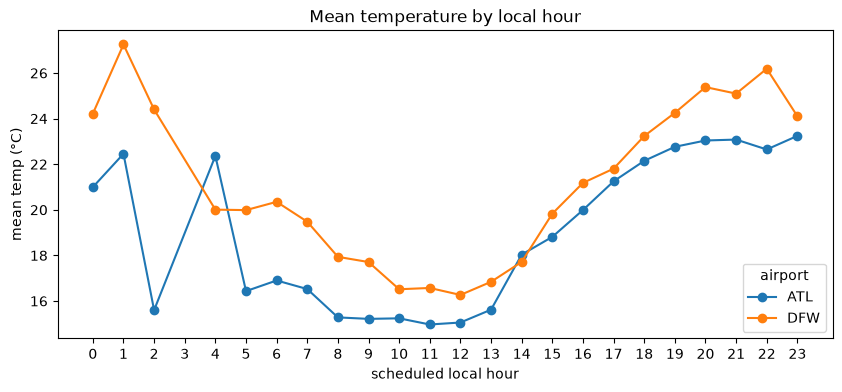

hour of peak mean temperature: {'ATL': 23, 'DFW': 1}
hour of lowest mean temperature: {'ATL': 11, 'DFW': 12}


In [26]:
diurnal = hub_wx.groupby(["airport", "hour"])["temp"].mean().unstack(0)

fig, ax = plt.subplots(figsize=(10, 4))
diurnal.plot(ax=ax, marker="o")
ax.set_xticks(range(24))
ax.set_xlabel("scheduled local hour")
ax.set_ylabel("mean temp (°C)")
ax.set_title("Mean temperature by local hour")
plt.show()

print("hour of peak mean temperature:", diurnal.idxmax().to_dict())
print("hour of lowest mean temperature:", diurnal.idxmin().to_dict())

## C. Hourly Weather Series

Rebuild one hourly weather timeline per airport, confirm the time zone finding from B6, convert to the true weather time,
and check whether weather from 3-12 hours before a flight is available.

### C1. One weather table per airport

B1-B2 showed weather was joined on (flight date, airport, **scheduled** hour), and that origin and destination weather agree.
Here we rebuild that lookup table: one row per (date, airport, key hour), and flag keys where flights disagree.

`key_hour` is the scheduled local hour the join used. It is **not yet** the true time of the weather reading (see C2-C3).

In [27]:
o = df[["FL_DATE", "ORIGIN"] + WX_ORIGIN].copy()
o["key_hour"] = hour_of(df["CRS_DEP_TIME"])
o.columns = ["date", "airport"] + WX + ["key_hour"]

d = df[["FL_DATE", "DEST"] + WX_DEST].copy()
d["key_hour"] = hour_of(df["CRS_ARR_TIME"])
d.columns = ["date", "airport"] + WX + ["key_hour"]

wx_long = pd.concat([o, d], ignore_index=True)
KEY = ["date", "airport", "key_hour"]

n_values = wx_long.groupby(KEY)[WX].nunique()
conflicts = n_values[n_values.max(axis=1) > 1]
wx = wx_long.groupby(KEY)[WX].first().reset_index()

print(f"weather table: {len(wx):,} rows across {wx['airport'].nunique()} airports")
print(f"keys with conflicting values: {len(conflicts):,} ({len(conflicts) / len(n_values):.2%})")
print("columns that disagree in those keys:")
print((conflicts > 1).sum())

weather table: 252,706 rows across 350 airports
keys with conflicting values: 27 (0.01%)
columns that disagree in those keys:
temp    27
prcp     0
wspd     0
wpgt     0
pres    27
snow     0
coco     0
dtype: int64


In [28]:
# Examples of conflicting keys
example_keys = conflicts.head(3).index
wx_long.set_index(KEY).loc[example_keys].sort_index()

temp  prcp  wspd  wpgt         pres  snow  \
date       airport key_hour                                                   
2023-03-02 SJU     22        16.707647   0.0   0.0   0.0  1015.873971   0.0   
                   22        17.095449   0.0   0.0   0.0  1015.852420   0.0   
2023-05-03 SJU     23        16.707647   0.0   0.0   0.0  1015.873971   0.0   
                   23        17.095449   0.0   0.0   0.0  1015.852420   0.0   
2023-08-06 SJU     12        16.707647   0.0   0.0   0.0  1015.873971   0.0   
                   12        17.095449   0.0   0.0   0.0  1015.852420   0.0   

                             coco  
date       airport key_hour        
2023-03-02 SJU     22         0.0  
                   22         0.0  
2023-05-03 SJU     23         0.0  
                   23         0.0  
2023-08-06 SJU     12         0.0  
                   12         0.0

### C2. Daylight-saving check

B6 suggested the weather is in UTC but was looked up with the flight's local clock hour.
Test: compare the mean temperature curve (by `key_hour`) in the 3 weeks before vs after each clock change.
Sunrise barely moves in that window, but local clocks jump 1 hour.

- **Weather in UTC:** UTC does not change at daylight saving, so the curve should **not** shift (best shift = 0).
- **Weather in local clock time:** the curve should shift by about **1 hour**.

Each curve is centred on its own mean so seasonal warming/cooling does not affect the match.

In [29]:
HUBS = ["ATL", "DFW"]
DST_CHANGES = pd.to_datetime(["2023-03-12", "2023-11-05", "2024-03-10", "2024-11-03", "2025-03-09"])
WINDOW = pd.Timedelta(days=21)

def temp_curve(data):
    """Mean temperature by key hour (only hours with 3+ readings), centred on its mean."""
    g = data.groupby("key_hour")["temp"].agg(["mean", "size"])
    curve = g.loc[g["size"] >= 3, "mean"]
    return curve - curve.mean()

def best_shift(before, after, shifts=range(-3, 4)):
    """Hour shift of `after` that best matches `before` (lowest mean squared difference)."""
    errors = {}
    for s in shifts:
        shifted = after.copy()
        shifted.index = (shifted.index + s) % 24
        common = before.index.intersection(shifted.index)
        errors[s] = ((before[common] - shifted[common]) ** 2).mean()
    return min(errors, key=errors.get), errors

rows = []
curves = {}
for h in HUBS:
    hub = wx[wx["airport"] == h]
    for t in DST_CHANGES:
        before = temp_curve(hub[(hub["date"] >= t - WINDOW) & (hub["date"] < t)])
        after = temp_curve(hub[(hub["date"] >= t) & (hub["date"] < t + WINDOW)])
        shift, errors = best_shift(before, after)
        curves[(h, t)] = (before, after)
        rows.append({"airport": h, "clock_change": t.date(), "best_shift_hours": shift,
                     "error_at_0": round(errors[0], 2), "error_at_best": round(errors[shift], 2)})

dst_check = pd.DataFrame(rows)
dst_check

,airport,clock_change,best_shift_hours,error_at_0,error_at_best
0,ATL,2023-03-12,1,3.72,3.41
1,ATL,2023-11-05,0,1.75,1.75
2,ATL,2024-03-10,1,1.27,1.18
3,ATL,2024-11-03,-1,5.37,4.86
4,ATL,2025-03-09,-1,2.47,2.29
5,DFW,2023-03-12,2,10.57,5.62
6,DFW,2023-11-05,-1,3.04,1.88
7,DFW,2024-03-10,-1,8.97,6.41
8,DFW,2024-11-03,0,1.52,1.52
9,DFW,2025-03-09,1,10.56,10.22


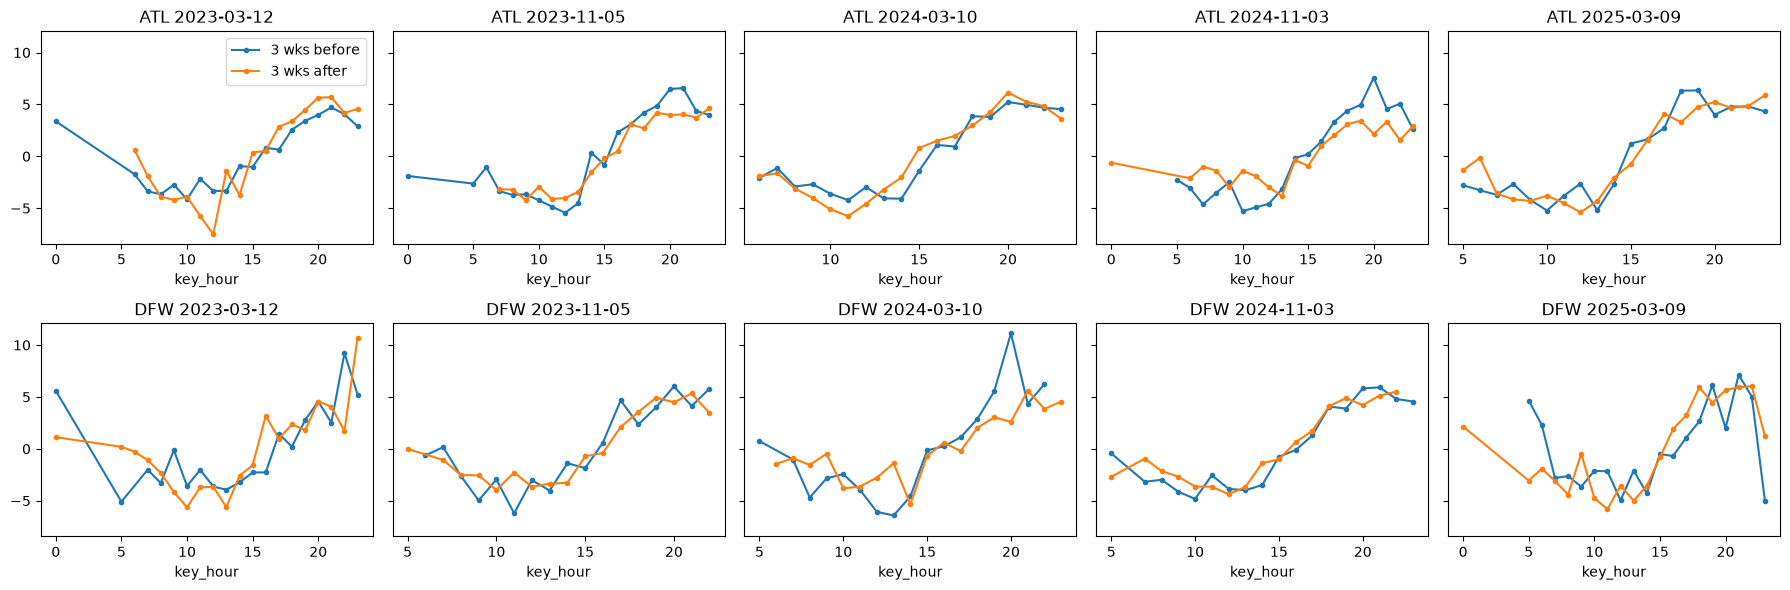

In [30]:
fig, axes = plt.subplots(len(HUBS), len(DST_CHANGES), figsize=(18, 6), sharey=True)
for i, h in enumerate(HUBS):
    for j, t in enumerate(DST_CHANGES):
        before, after = curves[(h, t)]
        ax = axes[i, j]
        before.plot(ax=ax, marker=".", label="3 wks before")
        after.plot(ax=ax, marker=".", label="3 wks after")
        ax.set_title(f"{h} {t.date()}")
        ax.set_xlabel("key_hour")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

### C3. Convert to the true weather time

**Assumes C2 confirms UTC.** Treat each weather row's (date, key hour) as a UTC timestamp, then convert it to the airport's local time.
Then measure how long before each ATL/DFW departure its attached weather was actually recorded.

The dataset has no time zone per airport, so ATL/DFW time zones are set by hand here. The any-airport pipeline will need a time zone source.

In [31]:
HUB_TZ = {"ATL": "America/New_York", "DFW": "America/Chicago"}

def local_flight_time(dates: pd.Series, hhmm: pd.Series, tz: str) -> pd.Series:
    """Flight date + HHMM local clock time -> timezone-aware timestamp."""
    hhmm = hhmm % 2400
    naive = dates + pd.to_timedelta(hhmm // 100, unit="h") + pd.to_timedelta(hhmm % 100, unit="m")
    return naive.dt.tz_localize(tz, ambiguous="NaT", nonexistent="shift_forward")

lags = []
for h, tz in HUB_TZ.items():
    deps = df[df["ORIGIN"] == h]
    flight_local = local_flight_time(deps["FL_DATE"], deps["CRS_DEP_TIME"], tz)
    weather_utc = (deps["FL_DATE"] + pd.to_timedelta(hour_of(deps["CRS_DEP_TIME"]), unit="h")).dt.tz_localize("UTC")
    hours_before = (flight_local - weather_utc).dt.total_seconds() / 3600
    lags.append(pd.DataFrame({"airport": h, "hours_before_flight": hours_before.round().astype("Int64")}))

lags = pd.concat(lags)
print("how many hours before the scheduled departure the attached weather was recorded:")
lags.groupby("airport")["hours_before_flight"].value_counts().unstack(0).fillna(0).astype(int)

how many hours before the scheduled departure the attached weather was recorded:


airport,ATL,DFW
hours_before_flight,,
4,3120,0
5,3902,2588
6,1393,4004
7,0,1144


In [32]:
# Hub weather series indexed by true UTC time (used in C4-C5)
hub_series = wx[wx["airport"].isin(HUBS)].copy()
hub_series["time_utc"] = (hub_series["date"] + pd.to_timedelta(hub_series["key_hour"], unit="h")).dt.tz_localize("UTC")
hub_series = hub_series.set_index("time_utc").sort_index()
hub_series.groupby("airport").size()

airport
ATL    9411
DFW    8310
dtype: int64

### C4. Coverage and gaps

Share of hours with a weather reading, by true local hour of day, and how long the runs of missing hours are.

ATL: 41.6% of hours have weather; missing runs median 2 h, 90th pct 8 h, max 19 h
DFW: 36.7% of hours have weather; missing runs median 2 h, 90th pct 9 h, max 20 h


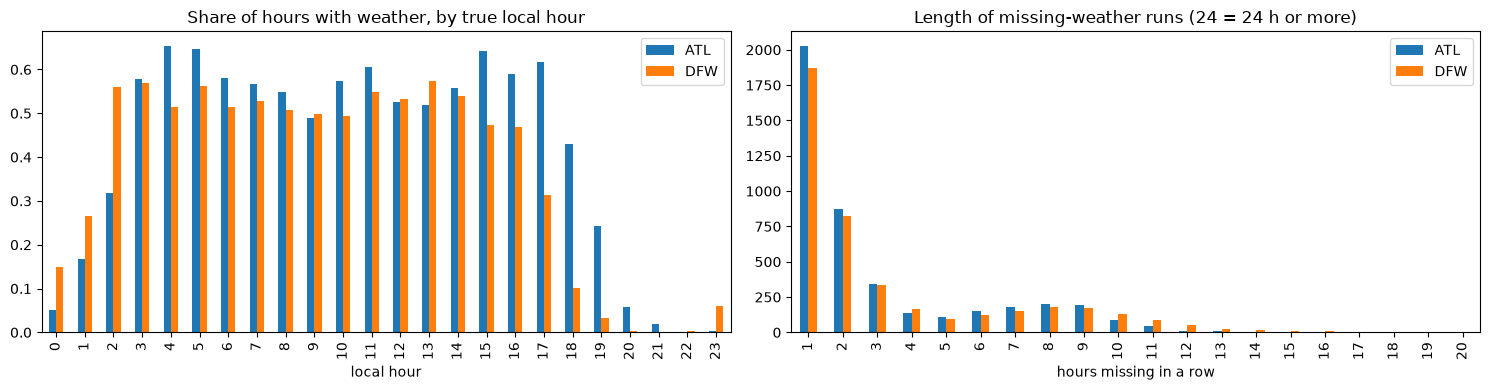

In [33]:
coverage = {}
gaps = {}
for h, tz in HUB_TZ.items():
    present = hub_series[hub_series["airport"] == h].index
    full = pd.date_range(present.min(), present.max(), freq="h")
    has = pd.Series(full.isin(present), index=full)

    coverage[h] = has.groupby(has.index.tz_convert(tz).hour).mean()

    run_id = (has != has.shift()).cumsum()
    runs = has.groupby(run_id).agg(["first", "size"])
    gaps[h] = runs.loc[~runs["first"], "size"]
    print(f"{h}: {has.mean():.1%} of hours have weather; "
          f"missing runs median {gaps[h].median():.0f} h, 90th pct {gaps[h].quantile(0.9):.0f} h, max {gaps[h].max()} h")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
pd.DataFrame(coverage).plot(kind="bar", ax=axes[0])
axes[0].set_title("Share of hours with weather, by true local hour")
axes[0].set_xlabel("local hour")
pd.DataFrame({h: g.clip(upper=24).value_counts().sort_index() for h, g in gaps.items()}).plot(kind="bar", ax=axes[1])
axes[1].set_title("Length of missing-weather runs (24 = 24 h or more)")
axes[1].set_xlabel("hours missing in a row")
plt.tight_layout()
plt.show()

### C5. Can we look back 3-12 hours?

For each ATL/DFW departure, is there a weather reading 3, 6, 9 and 12 hours before the scheduled departure?
Checked exactly (same hour) and with ±1 hour tolerance.

In [34]:
LOOKBACKS = [3, 6, 9, 12]
rows = []
for h, tz in HUB_TZ.items():
    present = hub_series[hub_series["airport"] == h].index
    deps = df[df["ORIGIN"] == h]
    flight_utc = local_flight_time(deps["FL_DATE"], deps["CRS_DEP_TIME"], tz).dt.tz_convert("UTC").dt.floor("h").dropna()
    for lb in LOOKBACKS:
        target = flight_utc - pd.Timedelta(hours=lb)
        exact = target.isin(present)
        near = exact | (target - pd.Timedelta(hours=1)).isin(present) | (target + pd.Timedelta(hours=1)).isin(present)
        rows.append({"airport": h, "hours_back": lb, "exact": exact.mean(), "within_1h": near.mean()})

lookback = pd.DataFrame(rows).pivot(index="hours_back", columns="airport")
lookback.round(3)

exact        within_1h       
airport       ATL    DFW       ATL    DFW
hours_back                               
3           0.535  0.457     0.951  0.805
6           0.521  0.656     0.904  1.000
9           0.396  0.404     0.693  0.724
12          0.339  0.308     0.605  0.571

## D. Targets

The two things the brief asks us to predict: severe departure delays (> 45 min) and the arrival rate (AAR).
This section describes them; it does not choose final definitions.

### D1. Defining "severe delay"

How often ATL/DFW departures are delayed over 45 minutes (departure vs arrival delay), the spread of delay minutes,
and how many flights were cancelled or diverted (these have no delay value, so they need a rule).

In [35]:
SEVERE_MIN = 45
CANCEL_REASONS = {"A": "airline", "B": "weather", "C": "air traffic system (NAS)", "D": "security"}

hub_dep = df[df["ORIGIN"].isin(HUBS)].copy()
hub_dep["dep_hour"] = hour_of(hub_dep["CRS_DEP_TIME"])

d1 = hub_dep.groupby("ORIGIN").agg(
    departures=("ORIGIN", "size"),
    with_dep_delay=("DEP_DELAY", "count"),
    dep_delay_over_45=("DEP_DELAY", lambda s: (s > SEVERE_MIN).sum()),
    arr_delay_over_45=("ARR_DELAY", lambda s: (s > SEVERE_MIN).sum()),
    cancelled=("CANCELLED", "sum"),
    diverted=("DIVERTED", "sum"),
)
d1["dep_rate_over_45"] = (d1["dep_delay_over_45"] / d1["with_dep_delay"]).round(3)
d1["arr_rate_over_45"] = (d1["arr_delay_over_45"] / d1["with_dep_delay"]).round(3)
d1

,departures,with_dep_delay,dep_delay_over_45,arr_delay_over_45,cancelled,diverted,dep_rate_over_45,arr_rate_over_45
ORIGIN,,,,,,,,
ATL,8415,8343,780,780,74.0,26.0,0.093,0.093
DFW,7736,7611,991,991,130.0,21.0,0.130,0.130


In [36]:
cancel_reasons = pd.crosstab(hub_dep["ORIGIN"], hub_dep["CANCELLATION_CODE"].map(CANCEL_REASONS))
print("cancellations by reason:")
cancel_reasons

cancellations by reason:


CANCELLATION_CODE,air traffic system (NAS),airline,weather
ORIGIN,,,
ATL,5,30,39
DFW,5,12,113


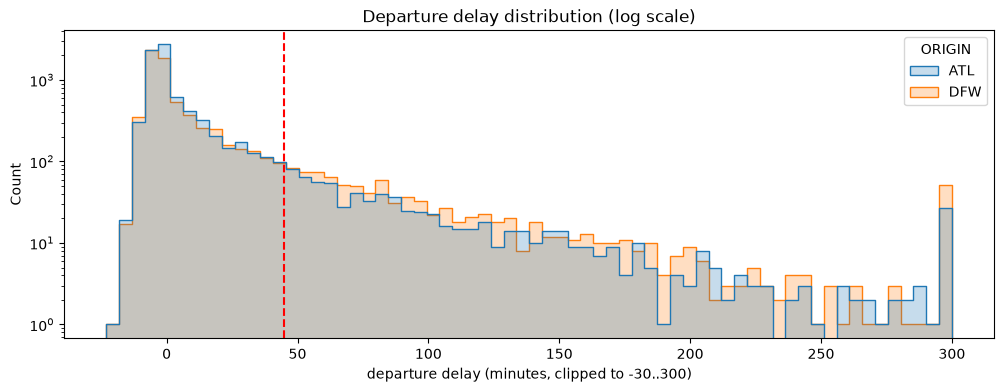

In [37]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.histplot(data=hub_dep, x=hub_dep["DEP_DELAY"].clip(-30, 300), hue="ORIGIN",
             bins=66, element="step", ax=ax)
ax.axvline(SEVERE_MIN, color="red", linestyle="--", label="45 min")
ax.set_yscale("log")
ax.set_xlabel("departure delay (minutes, clipped to -30..300)")
ax.set_title("Departure delay distribution (log scale)")
plt.show()

### D2. Delay patterns

Rate of > 45 min departure delays by scheduled hour, day of week and month, per airport.
A rate by hour and month is also the simplest baseline any model has to beat.

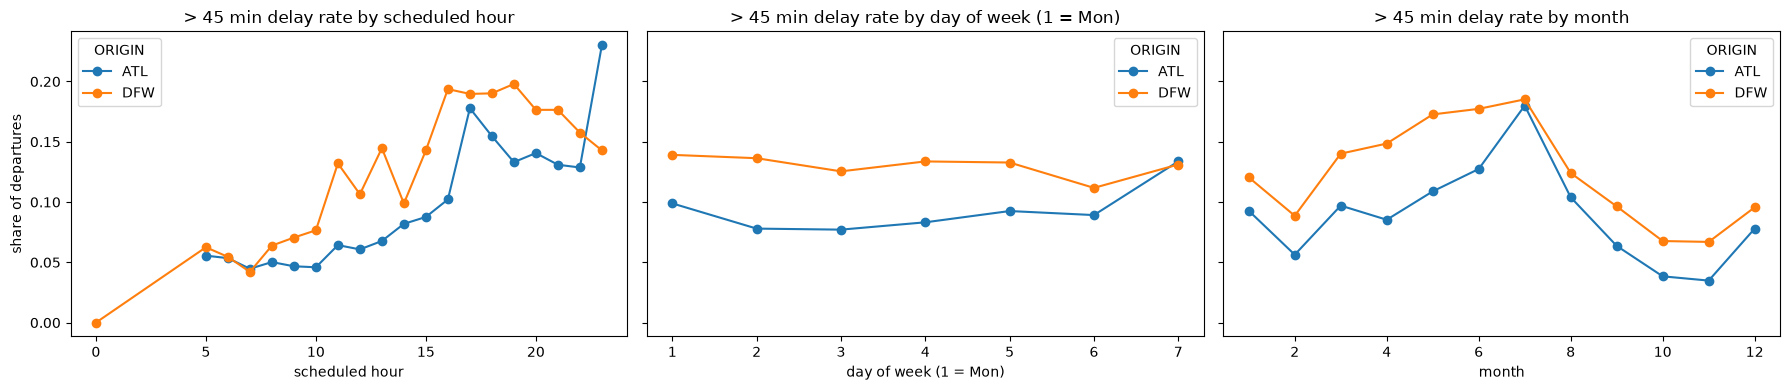

In [38]:
flown_dep = hub_dep[hub_dep["DEP_DELAY"].notna()].copy()
flown_dep["severe"] = flown_dep["DEP_DELAY"] > SEVERE_MIN

fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for ax, col, label in zip(axes, ["dep_hour", "DAY_OF_WEEK", "MONTH"],
                          ["scheduled hour", "day of week (1 = Mon)", "month"]):
    flown_dep.groupby([col, "ORIGIN"])["severe"].mean().unstack().plot(ax=ax, marker="o")
    ax.set_xlabel(label)
    ax.set_title(f"> 45 min delay rate by {label}")
axes[0].set_ylabel("share of departures")
plt.tight_layout()
plt.show()

### D3. Delay causes

For flights with a > 45 min departure delay, how the delay minutes split across causes.
Cause columns are only filled when the flight arrived 15+ minutes late, so a few severe departures have no breakdown.
NAS (air traffic system) delays include weather-driven traffic management, so weather's real share is larger than `WEATHER_DELAY` alone.

In [39]:
CAUSES = ["CARRIER_DELAY", "WEATHER_DELAY", "NAS_DELAY", "SECURITY_DELAY", "LATE_AIRCRAFT_DELAY"]
severe_flights = flown_dep[flown_dep["severe"]]

print("severe departures with a cause breakdown:")
print(severe_flights.groupby("ORIGIN")["CARRIER_DELAY"].apply(lambda s: f"{s.notna().mean():.1%}"))

minutes_share = severe_flights.groupby("ORIGIN")[CAUSES].sum()
minutes_share = minutes_share.div(minutes_share.sum(axis=1), axis=0).round(3)
flights_with_cause = severe_flights.groupby("ORIGIN")[CAUSES].apply(lambda g: (g > 0).mean()).round(3)

display(minutes_share.rename(columns=lambda c: c.replace("_DELAY", "").lower() + " (share of minutes)"))
display(flights_with_cause.rename(columns=lambda c: c.replace("_DELAY", "").lower() + " (share of flights)"))

severe departures with a cause breakdown:
ORIGIN
ATL    99.1%
DFW    99.6%
Name: CARRIER_DELAY, dtype: str


,carrier (share of minutes),weather (share of minutes),nas (share of minutes),security (share of minutes),late_aircraft (share of minutes)
ORIGIN,,,,,
ATL,0.441,0.073,0.130,0.001,0.355
DFW,0.301,0.095,0.087,0.001,0.516


,carrier (share of flights),weather (share of flights),nas (share of flights),security (share of flights),late_aircraft (share of flights)
ORIGIN,,,,,
ATL,0.708,0.073,0.356,0.003,0.497
DFW,0.635,0.151,0.333,0.003,0.696


### D4. Normalising delays

The brief warns against comparing raw delay minutes between big and small airports.
For the 20 busiest origin airports: total delay minutes (driven by volume) vs severe delay rate (normalised by flight count).

In [40]:
top20 = df["ORIGIN"].value_counts().head(20).index
by_airport = df[df["ORIGIN"].isin(top20) & df["DEP_DELAY"].notna()].groupby("ORIGIN").agg(
    departures=("DEP_DELAY", "size"),
    total_delay_minutes=("DEP_DELAY_NEW", "sum"),
    mean_delay_minutes=("DEP_DELAY_NEW", "mean"),
    severe_rate=("DEP_DELAY", lambda s: (s > SEVERE_MIN).mean()),
)
by_airport["rank_by_total_minutes"] = by_airport["total_delay_minutes"].rank(ascending=False).astype(int)
by_airport["rank_by_severe_rate"] = by_airport["severe_rate"].rank(ascending=False).astype(int)
by_airport.sort_values("total_delay_minutes", ascending=False).round(3)

,departures,total_delay_minutes,mean_delay_minutes,severe_rate,rank_by_total_minutes,rank_by_severe_rate
ORIGIN,,,,,,
DFW,7611,158176.0,20.783,0.130,1,2
DEN,7625,133921.0,17.563,0.115,2,7
ORD,6995,124439.0,17.790,0.115,3,8
ATL,8343,123369.0,14.787,0.093,4,16
CLT,5079,91256.0,17.967,0.119,5,5
MCO,3998,77201.0,19.310,0.125,6,3
LAS,4789,76898.0,16.057,0.103,7,11
EWR,3241,61568.0,18.997,0.116,8,6
DCA,3441,61301.0,17.815,0.101,9,12


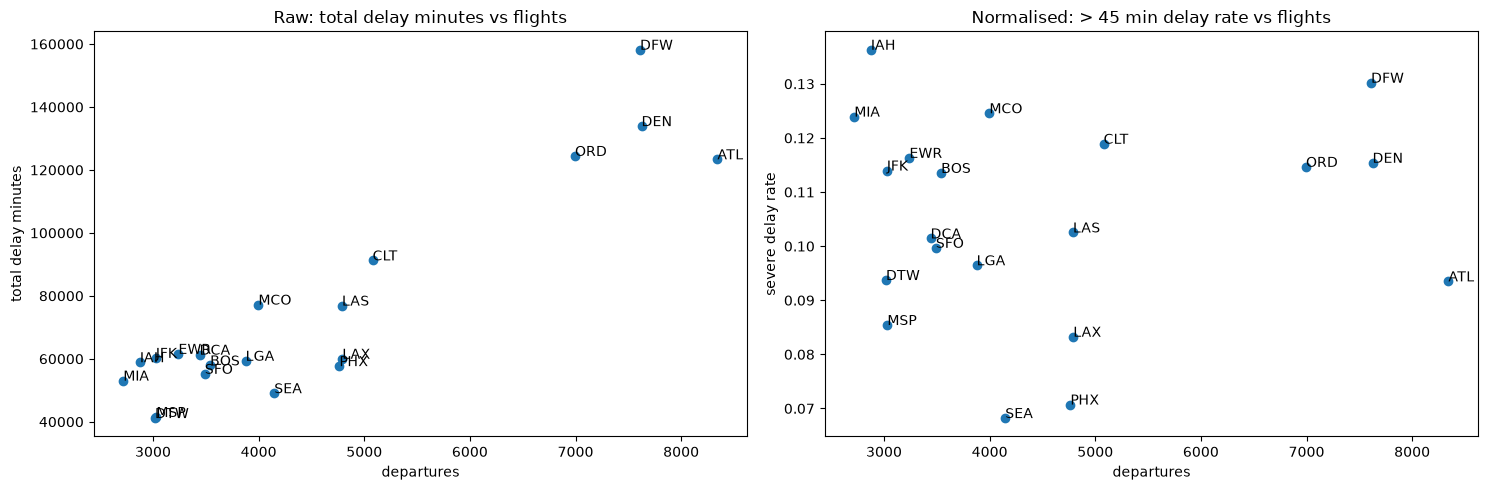

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(by_airport["departures"], by_airport["total_delay_minutes"])
axes[1].scatter(by_airport["departures"], by_airport["severe_rate"])
for code_, row in by_airport.iterrows():
    axes[0].annotate(code_, (row["departures"], row["total_delay_minutes"]))
    axes[1].annotate(code_, (row["departures"], row["severe_rate"]))
axes[0].set(title="Raw: total delay minutes vs flights", xlabel="departures", ylabel="total delay minutes")
axes[1].set(title="Normalised: > 45 min delay rate vs flights", xlabel="departures", ylabel="severe delay rate")
plt.tight_layout()
plt.show()

### D5. What can stand in for "arrival rate"?

Hourly arrival counts are too sparse (A4). Candidates, per airport:
- arrivals per 3-hour, 6-hour and daily window
- share of scheduled arrivals that actually landed (cancellations and diversions cut throughput)
- share of arrivals 15+ minutes late, mean arrival delay, NAS delay minutes

Then how the daily candidates move together. This informs the AAR definition; it does not choose one.

In [42]:
hub_arr = df[df["DEST"].isin(HUBS)].copy()
hub_arr["arr_hour"] = hour_of(hub_arr["CRS_ARR_TIME"])
hub_arr["landed"] = (hub_arr["CANCELLED"] == 0) & (hub_arr["DIVERTED"] == 0)

window_counts = {}
for h in HUBS:
    sub = hub_arr[hub_arr["DEST"] == h]
    for w in [3, 6, 24]:
        idx = pd.MultiIndex.from_product([all_dates, range(0, 24, w)], names=["date", "window"])
        counts = sub.groupby([sub["FL_DATE"], sub["arr_hour"] // w * w]).size()
        counts.index.names = ["date", "window"]
        window_counts[f"{h} {w}h"] = counts.reindex(idx, fill_value=0).describe()

print("arrivals per window (all windows, including empty ones):")
pd.DataFrame(window_counts).round(2)

arrivals per window (all windows, including empty ones):


,ATL 3h,ATL 6h,ATL 24h,DFW 3h,DFW 6h,DFW 24h
count,7544.00,3772.00,943.00,7544.00,3772.00,943.00
mean,0.72,1.44,5.76,0.53,1.07,4.28
std,0.94,1.42,2.55,0.79,1.18,2.19
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,4.00,0.00,0.00,3.00
50%,0.00,1.00,5.00,0.00,1.00,4.00
75%,1.00,2.00,7.00,1.00,2.00,6.00
max,7.00,8.00,18.00,6.00,7.00,14.00


ATL: daily proxy summary


,scheduled,landed_share,late_15_share,mean_arr_delay,nas_minutes
count,939.00,939.00,938.00,938.00,939.00
mean,5.78,0.99,0.19,6.27,15.18
std,2.53,0.07,0.20,26.41,35.30
min,1.00,0.00,0.00,-36.50,0.00
25%,4.00,1.00,0.00,-9.09,0.00
50%,5.00,1.00,0.17,-0.76,0.00
75%,7.00,1.00,0.30,12.86,16.00
max,18.00,1.00,1.00,219.40,362.00


DFW: daily proxy summary


,scheduled,landed_share,late_15_share,mean_arr_delay,nas_minutes
count,926.00,926.00,925.00,925.00,926.00
mean,4.35,0.97,0.25,13.95,18.35
std,2.13,0.10,0.26,45.13,56.83
min,1.00,0.00,0.00,-71.00,0.00
25%,3.00,1.00,0.00,-8.80,0.00
50%,4.00,1.00,0.20,1.75,0.00
75%,6.00,1.00,0.40,22.67,18.00
max,14.00,1.00,1.00,518.50,923.00


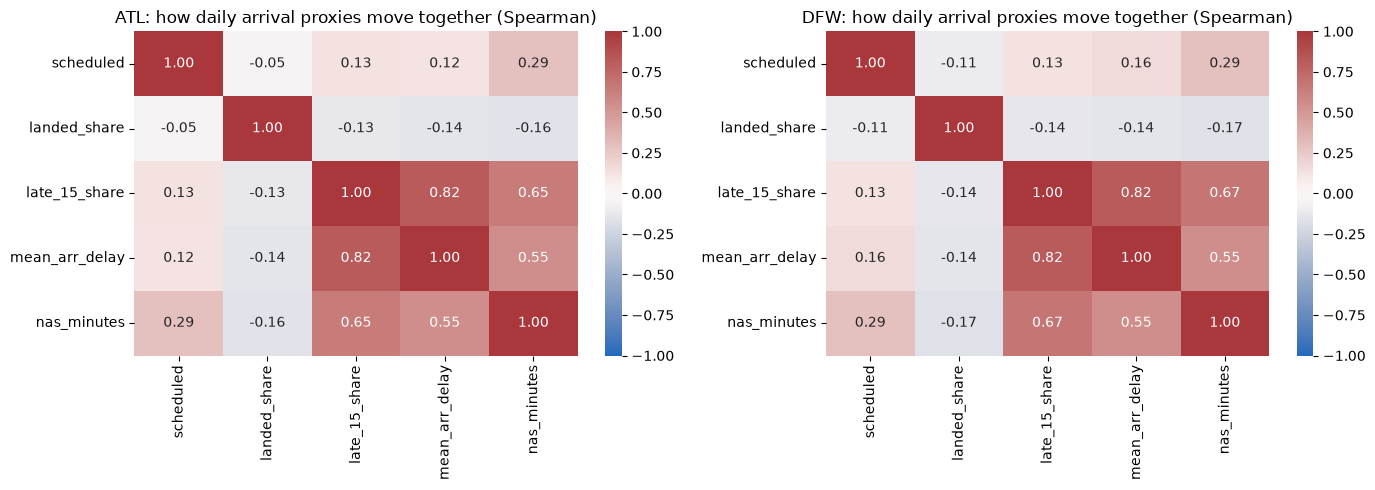

In [43]:
daily_arr = hub_arr.groupby(["DEST", "FL_DATE"]).agg(
    scheduled=("landed", "size"),
    landed_share=("landed", "mean"),
    late_15_share=("ARR_DEL15", "mean"),
    mean_arr_delay=("ARR_DELAY", "mean"),
    nas_minutes=("NAS_DELAY", "sum"),
)

for h in HUBS:
    print(f"{h}: daily proxy summary")
    display(daily_arr.loc[h].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, h in zip(axes, HUBS):
    sns.heatmap(daily_arr.loc[h].corr(method="spearman"), annot=True, fmt=".2f",
                cmap="vlag", vmin=-1, vmax=1, ax=ax)
    ax.set_title(f"{h}: how daily arrival proxies move together (Spearman)")
plt.tight_layout()
plt.show()

### D6. How noisy are daily rates?

With ~9 departures a day, a daily severe-delay rate swings a lot. Spread of daily rates, and how many days count as "bad" at a few thresholds.

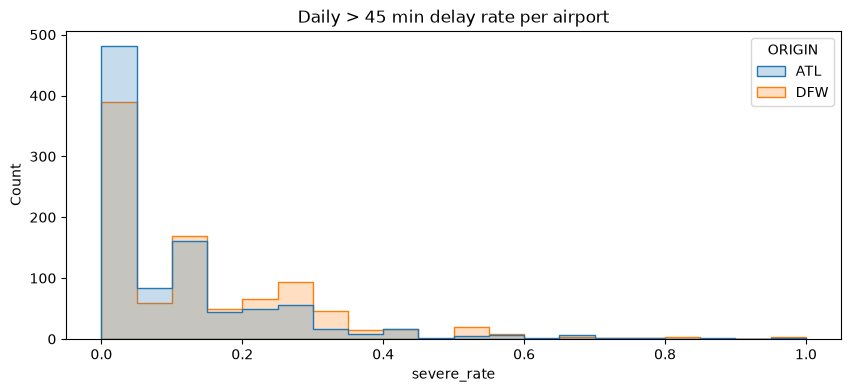

,rate >= 20%,rate >= 30%,rate >= 50%,2+ severe flights,days
ORIGIN,,,,,
ATL,172,72,24,183,943
DFW,275,128,40,252,942


In [44]:
daily_dep = flown_dep.groupby(["ORIGIN", "FL_DATE"]).agg(
    flights=("severe", "size"),
    severe_flights=("severe", "sum"),
    severe_rate=("severe", "mean"),
)

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(data=daily_dep.reset_index(), x="severe_rate", hue="ORIGIN", bins=20, element="step", ax=ax)
ax.set_title("Daily > 45 min delay rate per airport")
plt.show()

bad_days = pd.DataFrame({
    f"rate >= {t:.0%}": daily_dep.groupby("ORIGIN")["severe_rate"].apply(lambda s: (s >= t).sum())
    for t in [0.2, 0.3, 0.5]
})
bad_days["2+ severe flights"] = daily_dep.groupby("ORIGIN")["severe_flights"].apply(lambda s: (s >= 2).sum())
bad_days["days"] = daily_dep.groupby("ORIGIN").size()
bad_days

## E. Weather vs Delays

Does weather we would know 3-12 hours ahead predict severe (> 45 min) departure delays at ATL/DFW?
Uses the corrected weather timing from Section C: the weather attached to each flight is really ~4-7 h old (UTC assumption).

In [45]:
WX_GROUP_ORDER = ["clear/cloudy", "fog", "rain", "heavy rain", "snow/ice", "thunderstorm", "missing (0)"]
WX_SEVERITY = {"clear/cloudy": 0, "fog": 1, "rain": 2, "heavy rain": 3, "snow/ice": 3, "thunderstorm": 4}

def wx_group(coco) -> str:
    """Meteostat condition code -> broad weather group (labels assume Meteostat codes, see B4)."""
    if pd.isna(coco):
        return None
    c = int(coco)
    if c == 0:
        return "missing (0)"
    if c <= 4:
        return "clear/cloudy"
    if c in (5, 6):
        return "fog"
    if c in (7, 8, 17):
        return "rain"
    if c in (9, 18):
        return "heavy rain"
    if c >= 23:
        return "thunderstorm"
    return "snow/ice"

def rate_table(data: pd.DataFrame, col: str, order=None) -> pd.DataFrame:
    """Flights, severe rate and mean delay per value of `col`, per airport."""
    t = data.groupby([col, "ORIGIN"], observed=True).agg(
        flights=("severe", "size"),
        severe_rate=("severe", "mean"),
        mean_delay=("DEP_DELAY", "mean"),
    ).unstack("ORIGIN").round(3)
    if order is not None:
        t = t.reindex([o for o in order if o in t.index])
    return t

e = flown_dep.copy()
e["wx_group"] = e["coco_ORIGIN"].map(wx_group)
e["prcp_band"] = pd.cut(e["prcp_ORIGIN"], [-0.1, 0, 1, 5, np.inf], labels=["0", "0-1 mm", "1-5 mm", "> 5 mm"])
e["wspd_band"] = pd.cut(e["wspd_ORIGIN"], [-0.1, 10, 20, 30, 40, np.inf], labels=["0-10", "10-20", "20-30", "30-40", "> 40 km/h"])
e["pres_band"] = pd.cut(e["pres_ORIGIN"], [0, 1005, 1012, 1020, np.inf], labels=["< 1005", "1005-1012", "1012-1020", "> 1020 hPa"])
e["temp_band"] = pd.cut(e["temp_ORIGIN"], [-np.inf, 0, 10, 20, 30, np.inf], labels=["< 0", "0-10", "10-20", "20-30", "> 30 °C"])

### E1. Severe delay rate by attached weather

The weather attached to each departure (~5 h before it). Check flight counts: small groups give unreliable rates.

In [46]:
display(rate_table(e, "wx_group", WX_GROUP_ORDER))
for col in ["prcp_band", "wspd_band", "pres_band", "temp_band"]:
    print(f"\n{col}")
    display(rate_table(e, col))

flights         severe_rate        mean_delay        
ORIGIN           ATL     DFW         ATL    DFW        ATL     DFW
wx_group                                                          
clear/cloudy  7009.0  6807.0       0.079  0.116     10.267  15.869
fog            303.0   168.0       0.109  0.173     19.304  22.423
rain           780.0   469.0       0.181  0.239     24.447  38.164
heavy rain     208.0   133.0       0.149  0.376     19.582  57.910
snow/ice         NaN     8.0         NaN  0.125        NaN  25.625
thunderstorm    40.0    23.0       0.500  0.391     59.625  52.348
missing (0)      3.0     3.0       0.000  0.000      2.667  10.667


prcp_band


flights       severe_rate        mean_delay        
ORIGIN        ATL   DFW         ATL    DFW        ATL     DFW
prcp_band                                                    
0            7878  7344       0.089  0.126     11.603  17.586
0-1 mm        260   134       0.154  0.269     22.838  43.828
1-5 mm        144    93       0.160  0.247     21.083  29.903
> 5 mm         61    40       0.311  0.250     48.525  25.525


wspd_band


flights       severe_rate        mean_delay        
ORIGIN        ATL   DFW         ATL    DFW        ATL     DFW
wspd_band                                                    
0-10         3049  1920       0.072  0.115      9.539  14.521
10-20        3824  3053       0.099  0.117     12.946  17.035
20-30        1273  2112       0.119  0.151     16.075  21.304
30-40         180   438       0.128  0.160     20.744  23.854
> 40 km/h      17    88       0.235  0.273     32.824  39.750


pres_band


flights       severe_rate        mean_delay        
ORIGIN         ATL   DFW         ATL    DFW        ATL     DFW
pres_band                                                     
< 1005          88   258       0.205  0.202     25.614  27.109
1005-1012     1067  2134       0.126  0.138     16.608  19.912
1012-1020     4731  3783       0.102  0.135     13.794  18.828
> 1020 hPa    2457  1436       0.059  0.093      7.371  12.615


temp_band


flights       severe_rate        mean_delay        
ORIGIN        ATL   DFW         ATL    DFW        ATL     DFW
temp_band                                                    
< 0           174   160       0.069  0.169      8.540  25.550
0-10         1430  1115       0.067  0.099      8.407  11.628
10-20        2766  2106       0.068  0.112      9.495  16.265
20-30        3289  3105       0.103  0.129     13.704  17.525
> 30 °C       684  1125       0.211  0.196     27.050  29.427

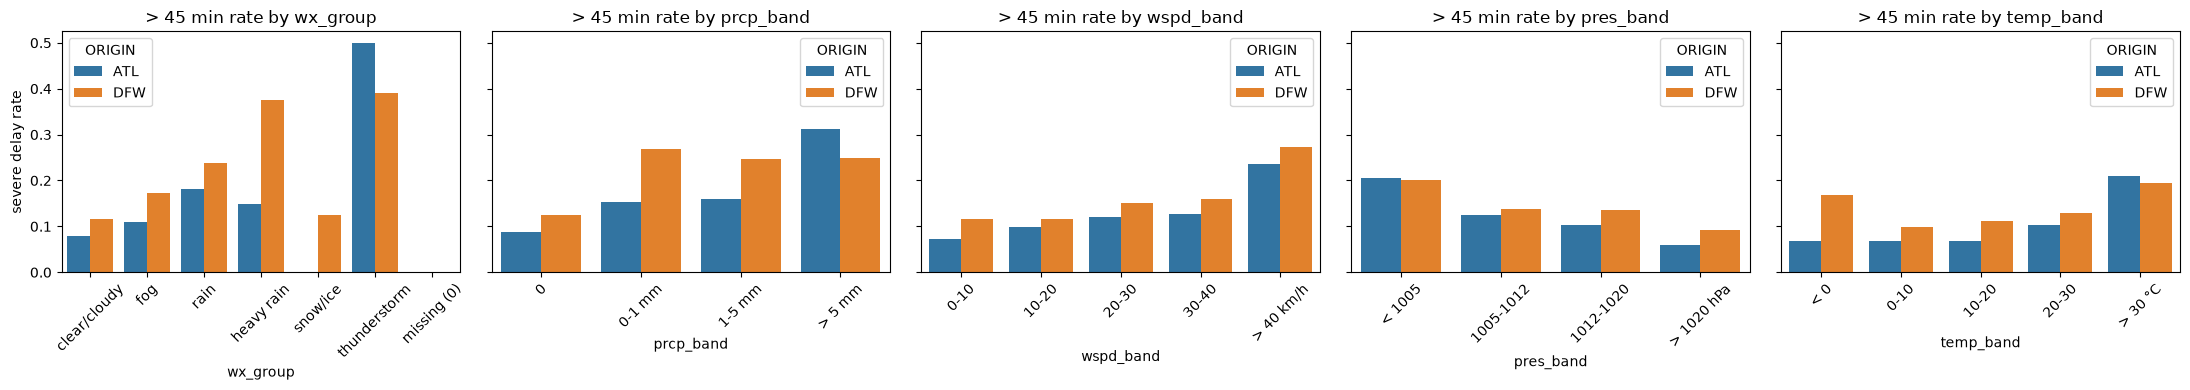

In [47]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4), sharey=True)
for ax, col in zip(axes, ["wx_group", "prcp_band", "wspd_band", "pres_band", "temp_band"]):
    order = [o for o in WX_GROUP_ORDER if o in set(e[col])] if col == "wx_group" else None
    sns.barplot(data=e, x=col, y="severe", hue="ORIGIN", order=order, errorbar=None, ax=ax)
    ax.set_title(f"> 45 min rate by {col}")
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("severe delay rate")
plt.tight_layout()
plt.show()

### E2. Delay minutes by weather group

The full spread of departure delay minutes, not just averages (outliers hidden, clipped to -30..300).

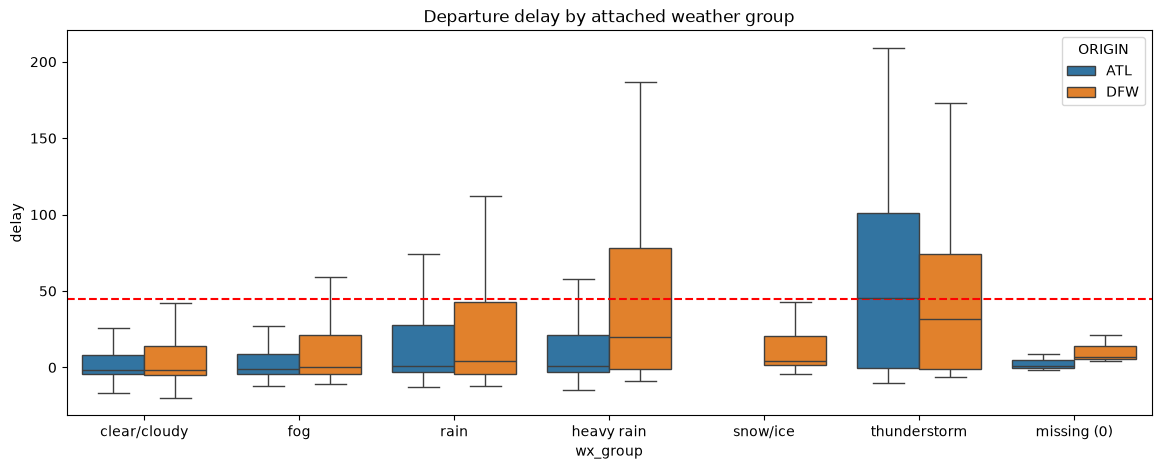

In [48]:
fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=e.assign(delay=e["DEP_DELAY"].clip(-30, 300)), x="wx_group", y="delay", hue="ORIGIN",
            order=[o for o in WX_GROUP_ORDER if o in set(e["wx_group"])], showfliers=False, ax=ax)
ax.axhline(SEVERE_MIN, color="red", linestyle="--")
ax.set_title("Departure delay by attached weather group")
plt.show()

### E3. Looking back 3, 6, 9 and 12 hours

For each departure (including cancelled ones, used in E5), weather from the rebuilt hourly series that many hours before the scheduled departure (±1 h).
Then the severe rate per weather group at each lookback, and its **lift** = group rate / overall rate at that lookback.

In [49]:
LOOKBACKS = [3, 6, 9, 12]

def weather_at(times: pd.Series, series: pd.DataFrame) -> pd.DataFrame:
    """Weather at each time (exact hour, else 1 h earlier, else 1 h later). Returned in the same order as `times`."""
    times = times.reset_index(drop=True)
    out = series.reindex(times).reset_index(drop=True)
    for shift in [-1, 1]:
        alt = series.reindex(times + pd.Timedelta(hours=shift)).reset_index(drop=True)
        out = out.combine_first(alt)
    return out[series.columns]

parts = []
for h, tz in HUB_TZ.items():
    series = hub_series.loc[hub_series["airport"] == h, WX]
    flights = hub_dep[hub_dep["ORIGIN"] == h].reset_index(drop=True)
    flight_utc = local_flight_time(flights["FL_DATE"], flights["CRS_DEP_TIME"], tz).dt.tz_convert("UTC").dt.floor("h")
    for lb in LOOKBACKS:
        wx_then = weather_at(flight_utc - pd.Timedelta(hours=lb), series)
        part = flights[["ORIGIN", "FL_DATE", "dep_hour", "MONTH", "DEP_DELAY", "CANCELLED", "CANCELLATION_CODE"]].copy()
        part["lookback"] = lb
        parts.append(pd.concat([part, wx_then], axis=1))

lagged = pd.concat(parts, ignore_index=True)
lagged["severe"] = (lagged["DEP_DELAY"] > SEVERE_MIN).where(lagged["DEP_DELAY"].notna())
lagged["wx_group"] = lagged["coco"].map(wx_group)
lagged["weather_cancel"] = lagged["CANCELLATION_CODE"].eq("B")

print("share of departures with weather found at each lookback:")
lagged.groupby(["lookback", "ORIGIN"])["temp"].apply(lambda s: s.notna().mean()).unstack().round(3)

share of departures with weather found at each lookback:


ORIGIN,ATL,DFW
lookback,,
3,0.951,0.805
6,0.904,1.000
9,0.693,0.724
12,0.605,0.571


In [50]:
flown_lagged = lagged[lagged["severe"].notna() & lagged["wx_group"].notna()].copy()
flown_lagged["severe"] = flown_lagged["severe"].astype(bool)

by_group = flown_lagged.groupby(["ORIGIN", "lookback", "wx_group"]).agg(
    flights=("severe", "size"), severe_rate=("severe", "mean"))
overall = flown_lagged.groupby(["ORIGIN", "lookback"])["severe"].mean()
by_group["lift"] = by_group["severe_rate"] / overall.reindex(by_group.index.droplevel("wx_group")).values

lift_table = by_group["lift"].unstack("wx_group")[[g for g in WX_GROUP_ORDER if g in by_group.index.get_level_values("wx_group")]]
flights_table = by_group["flights"].unstack("wx_group")[lift_table.columns]
print("lift (severe rate in group / overall rate). 1.0 = no effect")
display(lift_table.round(2))
print("flights per group (small counts = unreliable lift)")
display(flights_table.fillna(0).astype(int))

lift (severe rate in group / overall rate). 1.0 = no effect


wx_group         clear/cloudy   fog  rain  heavy rain  snow/ice  thunderstorm  \
ORIGIN lookback                                                                 
ATL    3                 0.85  0.98  1.96        1.39       NaN          4.65   
       6                 0.87  1.22  1.79        1.70       NaN          4.33   
       9                 0.89  1.37  1.62        1.86       NaN          1.99   
       12                0.92  1.81  1.21        1.17       NaN          2.03   
DFW    3                 0.90  1.29  1.63        2.80      2.24          3.78   
       6                 0.90  1.24  1.85        2.75      0.96          2.43   
       9                 0.89  1.44  1.90        2.47      0.00          2.98   
       12                0.93  1.23  1.53        1.22      1.77          3.54   

wx_group         missing (0)  
ORIGIN lookback               
ATL    3                 0.0  
       6                 0.0  
       9                 0.0  
       12                NaN  
DFW    3                 0.0  
       6                 0.0  
       9                 NaN  
       12                NaN

flights per group (small counts = unreliable lift)


wx_group         clear/cloudy  fog  rain  heavy rain  snow/ice  thunderstorm  \
ORIGIN lookback                                                                
ATL    3                 6637  280   742         219         0            52   
       6                 6368  280   662         195         0            32   
       9                 4874  244   526         115         0            14   
       12                4215  224   467         113         0            26   
DFW    3                 5508  122   366          98         7            27   
       6                 6801  167   493         120         8            19   
       9                 4887  154   357          76         8            18   
       12                3816  136   296          61         7            21   

wx_group         missing (0)  
ORIGIN lookback               
ATL    3                   3  
       6                   4  
       9                   2  
       12                  0  
DFW    3                   2  
       6                   3  
       9                   0  
       12                  0

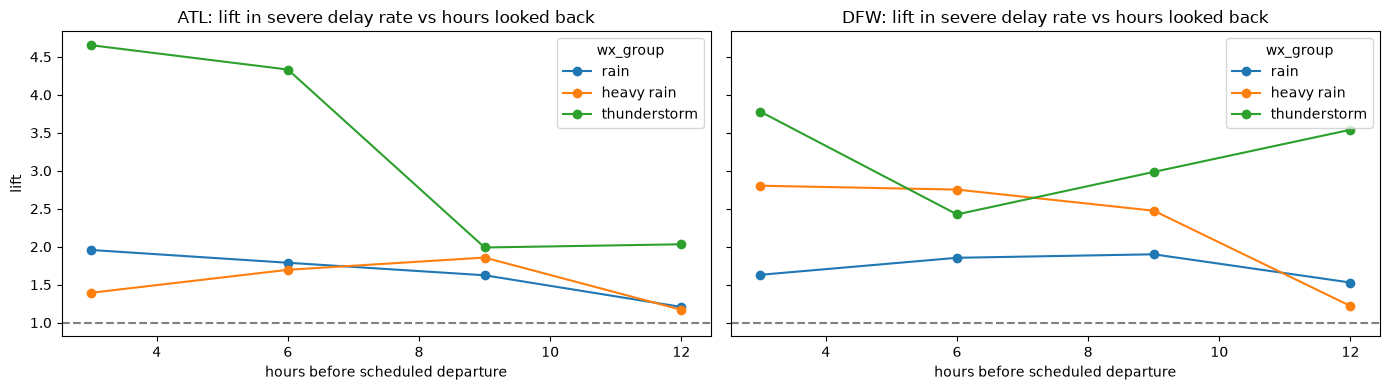

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, h in zip(axes, HUBS):
    lift_table.loc[h][["rain", "heavy rain", "thunderstorm"]].plot(ax=ax, marker="o")
    ax.axhline(1, color="grey", linestyle="--")
    ax.set_title(f"{h}: lift in severe delay rate vs hours looked back")
    ax.set_xlabel("hours before scheduled departure")
axes[0].set_ylabel("lift")
plt.tight_layout()
plt.show()

### E4. Is it weather, or just time of day and season?

Rain and delays both peak in summer afternoons. Each flight's outcome minus the typical severe rate for its airport, scheduled hour and month (the D2 baseline).
If bad weather still shows a positive **excess**, weather adds information beyond time of day and season.
Note: the baseline is computed on the same data (fine for exploration, not for model evaluation).

In [52]:
baseline = flown_dep.groupby(["ORIGIN", "dep_hour", "MONTH"])["severe"].mean().rename("baseline_rate")

e = e.join(baseline, on=["ORIGIN", "dep_hour", "MONTH"])
e["excess"] = e["severe"] - e["baseline_rate"]
flown_lagged = flown_lagged.join(baseline, on=["ORIGIN", "dep_hour", "MONTH"])
flown_lagged["excess"] = flown_lagged["severe"] - flown_lagged["baseline_rate"]

attached_excess = e.groupby(["ORIGIN", "wx_group"])["excess"].agg(["size", "mean"])
attached_excess = attached_excess.assign(lookback="attached (~5 h)").set_index("lookback", append=True)
lagged_excess = flown_lagged.groupby(["ORIGIN", "wx_group", "lookback"])["excess"].agg(["size", "mean"])
lagged_excess.index = lagged_excess.index.set_levels(lagged_excess.index.levels[2].astype(str) + " h", level=2)

excess = pd.concat([attached_excess, lagged_excess])["mean"].unstack("wx_group")
excess = excess[[g for g in WX_GROUP_ORDER if g in excess.columns]]
print("mean excess severe rate (percentage points above the hour x month baseline)")
(excess * 100).round(1)

mean excess severe rate (percentage points above the hour x month baseline)


wx_group                clear/cloudy  fog  rain  heavy rain  snow/ice  \
ORIGIN lookback                                                         
ATL    12 h                     -0.9  7.1   1.8         3.8       NaN   
       3 h                      -1.1  2.4   7.7         3.4       NaN   
       6 h                      -1.3  2.5   6.6         7.3       NaN   
       9 h                      -1.1  3.7   5.5         9.6       NaN   
       attached (~5 h)          -1.3  3.2   7.6         5.9       NaN   
DFW    12 h                     -0.8  5.1   8.6         6.9      17.5   
       3 h                      -1.2  6.9   8.1        19.2      16.9   
       6 h                      -1.3  4.5  10.3        21.6       2.0   
       9 h                      -1.4  7.0  11.9        22.9      -8.6   
       attached (~5 h)          -1.4  6.3  10.2        21.9       2.0   

wx_group                thunderstorm  missing (0)  
ORIGIN lookback                                    
ATL    12 h                      9.4          NaN  
       3 h                      24.4         -9.3  
       6 h                      17.9        -10.9  
       9 h                       7.7        -10.0  
       attached (~5 h)          28.1         -9.3  
DFW    12 h                     39.4          NaN  
       3 h                      32.2        -17.9  
       6 h                      14.0        -16.3  
       9 h                      26.3          NaN  
       attached (~5 h)          25.9        -16.3

### E5. Weather vs cancellations

Share of departures cancelled for weather (code B), by weather group: attached weather and at each lookback.

In [53]:
hub_dep_wx = hub_dep.assign(
    wx_group=hub_dep["coco_ORIGIN"].map(wx_group),
    weather_cancel=hub_dep["CANCELLATION_CODE"].eq("B"),
)
attached_cancel = hub_dep_wx.groupby(["ORIGIN", "wx_group"])["weather_cancel"].agg(["size", "mean"])
print("attached weather: weather-cancellation rate")
display(attached_cancel["mean"].unstack("wx_group").reindex(columns=WX_GROUP_ORDER).dropna(axis=1, how="all").round(3))

lagged_cancel = lagged[lagged["wx_group"].notna()].groupby(["ORIGIN", "lookback", "wx_group"])["weather_cancel"].mean()
print("by lookback: weather-cancellation rate")
lagged_cancel.unstack("wx_group").reindex(columns=WX_GROUP_ORDER).dropna(axis=1, how="all").round(3)

attached weather: weather-cancellation rate


wx_group,clear/cloudy,fog,rain,heavy rain,snow/ice,thunderstorm,missing (0)
ORIGIN,,,,,,,
ATL,0.003,0.003,0.008,0.019,0.8,0.048,0.0
DFW,0.008,0.040,0.058,0.076,0.5,0.148,0.0


by lookback: weather-cancellation rate


wx_group         clear/cloudy    fog   rain  heavy rain  snow/ice  \
ORIGIN lookback                                                     
ATL    3                0.003  0.000  0.008       0.013     0.750   
       6                0.003  0.007  0.010       0.005     0.400   
       9                0.004  0.004  0.007       0.017     0.750   
       12               0.004  0.004  0.006       0.009     0.800   
DFW    3                0.005  0.016  0.076       0.101     0.588   
       6                0.008  0.046  0.063       0.077     0.500   
       9                0.012  0.025  0.058       0.038     0.467   
       12               0.013  0.029  0.039       0.061     0.417   

wx_group         thunderstorm  missing (0)  
ORIGIN lookback                             
ATL    3                0.055          0.0  
       6                0.086          0.0  
       9                0.000          0.0  
       12               0.000          NaN  
DFW    3                0.129          0.0  
       6                0.050          0.0  
       9                0.000          NaN  
       12               0.000          NaN

### E6. Destination weather

Does bad weather at the destination raise departure delays at ATL/DFW (e.g. ground stops elsewhere)?
Caveat: destination time zones are not in the dataset, so this uses the destination weather as attached (the same UTC offset issue applies, so it is several hours old).

In [54]:
e["dest_wx_group"] = e["coco_DEST"].map(wx_group)
rate_table(e, "dest_wx_group", WX_GROUP_ORDER)

flights       severe_rate        mean_delay        
ORIGIN            ATL   DFW         ATL    DFW        ATL     DFW
dest_wx_group                                                    
clear/cloudy     6938  6407       0.088  0.126     11.522  17.527
fog               345   292       0.061  0.106      7.032  13.538
rain              616   514       0.131  0.163     18.831  23.599
heavy rain        207   179       0.159  0.184     24.005  24.575
snow/ice           68    67       0.132  0.164     16.338  30.104
thunderstorm       43    33       0.256  0.212     33.744  21.818
missing (0)       126   119       0.095  0.126     14.651  27.874

### E7. Overall strength of each signal

Spearman rank correlation between each weather variable and departure delay minutes, for the attached weather and each lookback.
`severity` ranks weather groups (clear 0, fog 1, rain 2, heavy rain / snow-ice 3, thunderstorm 4). Gust and snow are left out (unreliable / always 0, see B5).

In [55]:
SIGNALS = ["temp", "prcp", "wspd", "pres", "severity"]

attached = e.rename(columns={f"{w}_ORIGIN": w for w in WX}).assign(lookback="attached (~5 h)")
attached["severity"] = attached["wx_group"].map(WX_SEVERITY)
lag_signals = flown_lagged.assign(severity=flown_lagged["wx_group"].map(WX_SEVERITY),
                                  lookback=flown_lagged["lookback"].astype(str) + " h")

corr = (
    pd.concat([attached[["ORIGIN", "lookback", "DEP_DELAY"] + SIGNALS],
               lag_signals[["ORIGIN", "lookback", "DEP_DELAY"] + SIGNALS]])
    .groupby(["ORIGIN", "lookback"])
    .apply(lambda g: g[SIGNALS].corrwith(g["DEP_DELAY"], method="spearman"))
)
corr.round(3)

temp   prcp   wspd   pres  severity
ORIGIN lookback                                             
ATL    12 h             0.094  0.029 -0.011 -0.101     0.092
       3 h              0.119  0.087  0.077 -0.110     0.130
       6 h              0.116  0.077  0.057 -0.095     0.118
       9 h              0.120  0.042  0.058 -0.105     0.113
       attached (~5 h)  0.115  0.082  0.077 -0.103     0.129
DFW    12 h             0.110  0.053  0.044 -0.113     0.103
       3 h              0.124  0.106  0.086 -0.072     0.111
       6 h              0.105  0.069  0.071 -0.055     0.116
       9 h              0.111  0.070  0.052 -0.092     0.121
       attached (~5 h)  0.112  0.074  0.072 -0.058     0.123

## F. Runway Wind

The brief requires crosswind and tailwind relative to the runway (ATL heading 80°, DFW heading 180°, all flights use that heading).
The dataset has wind speed but **no wind direction**, so components cannot be computed directly.
This section shows the formula the pipeline will use if direction is available, and worst-case bounds from speed alone.

### F1. Wind components (formula)

For wind blowing **from** direction θ and runway heading H:
- headwind = speed × cos(θ − H) (negative = tailwind)
- crosswind = speed × sin(θ − H)

Example: 20 kt of wind at ATL (heading 80°) from different directions.
Because the brief fixes one heading per airport (no switching runway direction), wind from behind is always a tailwind.

In [56]:
RUNWAY_HEADING = {"ATL": 80, "DFW": 180}  # from the brief
KMH_PER_KT = 1.852

def wind_components(speed, wind_from_deg, runway_heading_deg):
    """Return (headwind, crosswind). Negative headwind = tailwind. Same units as speed."""
    angle = np.deg2rad(np.asarray(wind_from_deg) - runway_heading_deg)
    return speed * np.cos(angle), speed * np.sin(angle)

example_dirs = [80, 125, 170, 215, 260]
head, cross = wind_components(20, example_dirs, RUNWAY_HEADING["ATL"])
pd.DataFrame({"wind from (deg)": example_dirs, "headwind (kt)": head.round(1),
              "crosswind (kt)": np.abs(cross).round(1)})

,wind from (deg),headwind (kt),crosswind (kt)
0,80,20.0,0.0
1,125,14.1,14.1
2,170,0.0,20.0
3,215,-14.1,14.1
4,260,-20.0,0.0


### F2. Worst-case bounds from speed alone

Without direction, the worst case is that all the wind is crosswind or all of it is tailwind, so both are bounded by the wind speed.
Gusts are left out (unreliable, see B5).

**Reference limits (assumption, not from the dataset):** typical airline operating limits are about **10 kt tailwind** and **20-25 kt crosswind** (they vary by aircraft and runway condition).
Share of hours (corrected weather series) where the wind speed alone could exceed each limit:

share of hours where the limit COULD be exceeded (depends on unknown direction):


,could_exceed_tailwind,could_exceed_crosswind
airport,,
ATL,0.181,0.007
DFW,0.345,0.024


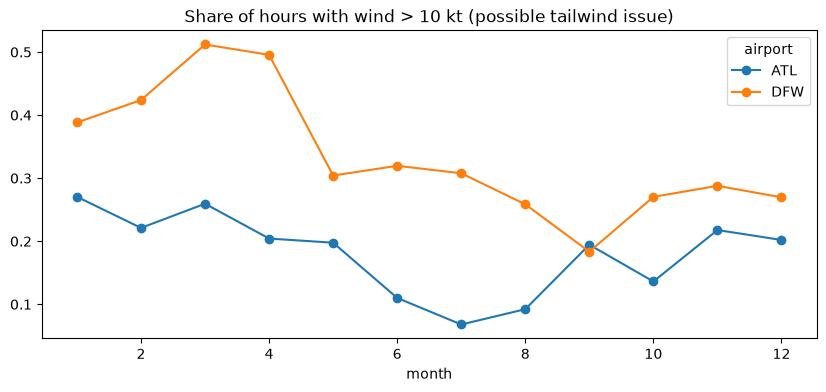

In [57]:
TAILWIND_LIMIT_KT = 10
CROSSWIND_LIMIT_KT = 20

wind = hub_series[["airport", "wspd"]].copy()
wind["wspd_kt"] = wind["wspd"] / KMH_PER_KT
wind["could_exceed_tailwind"] = wind["wspd_kt"] > TAILWIND_LIMIT_KT
wind["could_exceed_crosswind"] = wind["wspd_kt"] > CROSSWIND_LIMIT_KT

print("share of hours where the limit COULD be exceeded (depends on unknown direction):")
display(wind.groupby("airport")[["could_exceed_tailwind", "could_exceed_crosswind"]].mean().round(3))

local_month = pd.Series(
    [t.tz_convert(HUB_TZ[a]).month for t, a in zip(wind.index, wind["airport"])], index=wind.index)
monthly = wind.groupby([local_month.values, "airport"])["could_exceed_tailwind"].mean().unstack()
ax = monthly.plot(marker="o", figsize=(10, 4), title=f"Share of hours with wind > {TAILWIND_LIMIT_KT} kt (possible tailwind issue)")
ax.set_xlabel("month")
plt.show()

### F3. Delay rate by worst-case wind band

Severe delay rate by the attached wind speed (~5 h before departure), in bands relative to the reference limits.

In [58]:
e["wspd_kt_band"] = pd.cut(e["wspd_ORIGIN"] / KMH_PER_KT, [-0.1, TAILWIND_LIMIT_KT, CROSSWIND_LIMIT_KT, np.inf],
                           labels=[f"<= {TAILWIND_LIMIT_KT} kt", f"{TAILWIND_LIMIT_KT}-{CROSSWIND_LIMIT_KT} kt", f"> {CROSSWIND_LIMIT_KT} kt"])
rate_table(e, "wspd_kt_band")

flights       severe_rate        mean_delay        
ORIGIN           ATL   DFW         ATL    DFW        ATL     DFW
wspd_kt_band                                                    
<= 10 kt        6873  4973       0.087  0.116     11.434  16.064
10-20 kt        1423  2447       0.119  0.153     16.255  21.837
> 20 kt           47   191       0.191  0.199     34.574  28.832

## G. Severe Weather Periods

**Working definition (for exploration, not final):** an hour is "severe weather" if it is heavy rain, thunderstorm or snow/ice,
or precipitation > 5 mm, or wind > 40 km/h. Uses the corrected hourly series (true UTC times).

### G1. How often, and when?

severe-weather hours (of hours with weather):


,sum,mean
airport,,
ATL,361,0.038
DFW,326,0.039


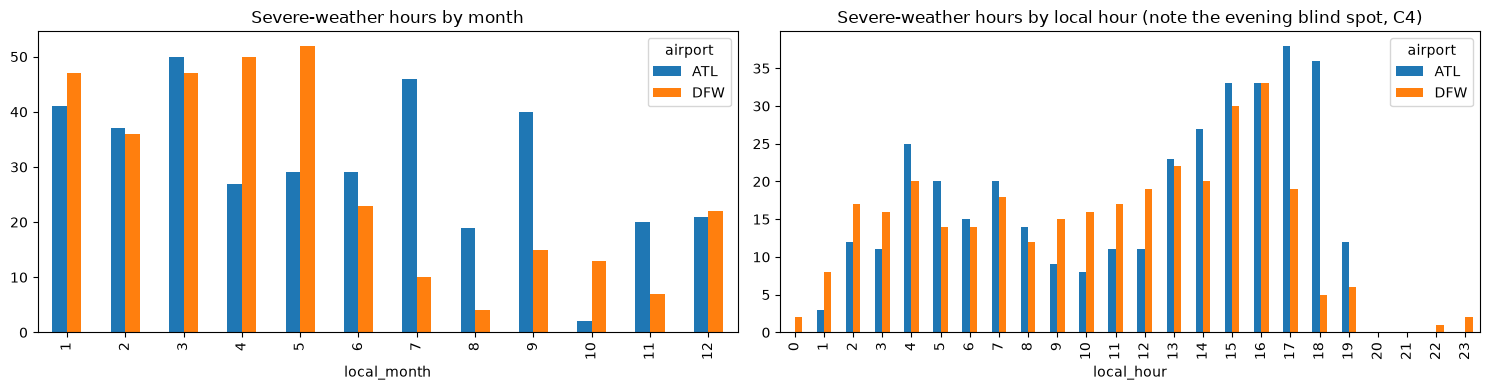

In [59]:
SEVERE_GROUPS = {"heavy rain", "thunderstorm", "snow/ice"}

hs = hub_series.copy()
hs["wx_group"] = hs["coco"].map(wx_group)
hs["severe_wx"] = hs["wx_group"].isin(SEVERE_GROUPS) | (hs["prcp"] > 5) | (hs["wspd"] > 40)
hs["local_time"] = [t.tz_convert(HUB_TZ[a]) for t, a in zip(hs.index, hs["airport"])]
hs["local_month"] = [t.month for t in hs["local_time"]]
hs["local_hour"] = [t.hour for t in hs["local_time"]]
hs["local_date"] = [t.date() for t in hs["local_time"]]

print("severe-weather hours (of hours with weather):")
display(hs.groupby("airport")["severe_wx"].agg(["sum", "mean"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
hs[hs["severe_wx"]].groupby(["local_month", "airport"]).size().unstack(fill_value=0).plot(kind="bar", ax=axes[0])
axes[0].set_title("Severe-weather hours by month")
hs[hs["severe_wx"]].groupby(["local_hour", "airport"]).size().unstack(fill_value=0).reindex(range(24), fill_value=0).plot(kind="bar", ax=axes[1])
axes[1].set_title("Severe-weather hours by local hour (note the evening blind spot, C4)")
plt.tight_layout()
plt.show()

### G2. Severe-weather events

Consecutive severe hours (gaps of up to 2 h allowed) grouped into events. Because weather is only seen in ~40% of hours,
event start and length are approximate: the true start may be earlier than the first observed severe hour.

In [60]:
def find_events(flags: pd.Series, max_gap_h: int = 2) -> pd.DataFrame:
    times = flags[flags].index.sort_values().to_series()
    new_event = times.diff() > pd.Timedelta(hours=max_gap_h)
    ev = times.groupby(new_event.cumsum().values).agg(["min", "max", "size"])
    ev.columns = ["start", "end", "severe_hours"]
    ev["span_hours"] = (ev["end"] - ev["start"]) / pd.Timedelta(hours=1) + 1
    return ev

events = pd.concat({h: find_events(hs.loc[hs["airport"] == h, "severe_wx"]) for h in HUBS}, names=["airport", "event"])
print(events.groupby("airport").size().rename("events").to_string())
events.groupby("airport")[["severe_hours", "span_hours"]].describe().round(1)

airport
ATL    204
DFW    197


severe_hours                                     span_hours            \
               count mean  std  min  25%  50%  75%   max      count mean  std   
airport                                                                         
ATL            204.0  1.8  1.4  1.0  1.0  1.0  2.0  10.0      204.0  2.0  1.9   
DFW            197.0  1.7  1.3  1.0  1.0  1.0  2.0  10.0      197.0  1.8  1.7   

                                   
         min  25%  50%  75%   max  
airport                            
ATL      1.0  1.0  1.0  2.0  15.0  
DFW      1.0  1.0  1.0  2.0  11.0

### G3. Delays and cancellations around events

For each ATL/DFW departure within 12 h of a severe-weather event start (nearest event), severe delay rate and weather-cancellation rate
by hours relative to the event start (2-hour bins). Negative = flight scheduled before the first observed severe hour.

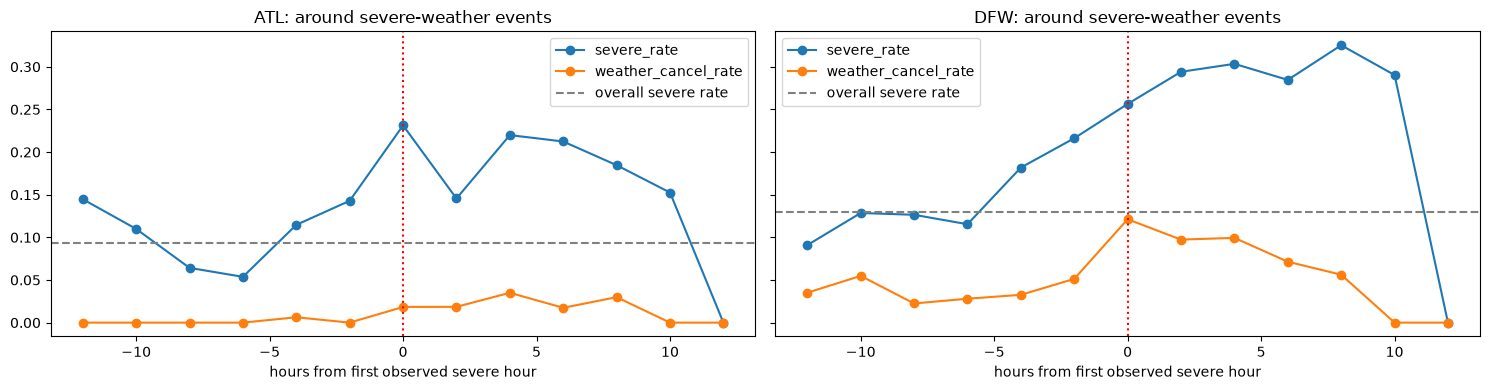

flights      severe_rate           weather_cancel_rate       
ORIGIN     ATL  DFW         ATL       DFW                 ATL    DFW
bin                                                                 
-12         76   57    0.144737  0.090909               0.000  0.035
-10         92   73     0.10989  0.128571               0.000  0.055
-8         111   89     0.06422  0.126437               0.000  0.022
-6         152  107    0.053691  0.115385               0.000  0.028
-4         159   92     0.11465  0.181818               0.006  0.033
-2         135  117    0.142857  0.216216               0.000  0.051
 0         163  132     0.23125   0.25641               0.018  0.121
 2         162  113     0.14557  0.294118               0.019  0.097
 4         200  161    0.219895  0.303448               0.035  0.099
 6         115  140    0.212389  0.284615               0.017  0.071
 8          67   89    0.184615  0.325301               0.030  0.056
 10         60   63    0.152542  0.290323               0.000  0.000
 12          1    1         0.0       0.0               0.000  0.000

In [61]:
rows = []
for h, tz in HUB_TZ.items():
    starts = np.sort(events.loc[h, "start"].dt.tz_convert("UTC").dt.tz_localize(None).values)
    flights = hub_dep[hub_dep["ORIGIN"] == h].reset_index(drop=True)
    futc = local_flight_time(flights["FL_DATE"], flights["CRS_DEP_TIME"], tz).dt.tz_convert("UTC").dt.tz_localize(None)
    ok = futc.notna().values
    fv = futc.values[ok]
    pos = np.clip(np.searchsorted(starts, fv), 1, len(starts) - 1)
    prev, nxt = starts[pos - 1], starts[pos]
    nearest = np.where(np.abs(fv - prev) <= np.abs(nxt - fv), prev, nxt)
    rel = (fv - nearest) / np.timedelta64(1, "h")
    part = flights.loc[ok, ["ORIGIN", "DEP_DELAY", "CANCELLATION_CODE"]].copy()
    part["rel_hours"] = rel
    rows.append(part[np.abs(rel) <= 12])

around = pd.concat(rows)
around["bin"] = (np.floor(around["rel_hours"] / 2) * 2).astype(int)
around["severe"] = (around["DEP_DELAY"] > SEVERE_MIN).where(around["DEP_DELAY"].notna())
around["weather_cancel"] = around["CANCELLATION_CODE"].eq("B")

study = around.groupby(["ORIGIN", "bin"]).agg(
    flights=("bin", "size"), severe_rate=("severe", "mean"), weather_cancel_rate=("weather_cancel", "mean"))
overall_rate = flown_dep.groupby("ORIGIN")["severe"].mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for ax, h in zip(axes, HUBS):
    s = study.loc[h]
    s[["severe_rate", "weather_cancel_rate"]].plot(ax=ax, marker="o")
    ax.axhline(overall_rate[h], color="grey", linestyle="--", label="overall severe rate")
    ax.axvline(0, color="red", linestyle=":")
    ax.set_title(f"{h}: around severe-weather events")
    ax.set_xlabel("hours from first observed severe hour")
    ax.legend()
plt.tight_layout()
plt.show()
study.unstack("ORIGIN").round(3)

### G4. Worst delay days: was severe weather seen?

The 15 worst days per airport by severe delay rate (days with 5+ departures), whether a severe-weather hour was observed that local day,
and the day's delay-cause split. Days with no observed weather are candidate **failure cases**: the blind spot or non-weather causes.

In [62]:
severe_days = hs[hs["severe_wx"]].groupby("airport")["local_date"].apply(set)

day_causes = flown_dep[flown_dep["severe"]].groupby(["ORIGIN", "FL_DATE"])[CAUSES].sum()
day_causes = day_causes.div(day_causes.sum(axis=1), axis=0)

worst = []
for h in HUBS:
    days = daily_dep.loc[h]
    top = days[days["flights"] >= 5].sort_values(["severe_rate", "flights"], ascending=False).head(15).copy()
    top["severe_wx_seen"] = [d.date() in severe_days.get(h, set()) for d in top.index]
    top = top.join(day_causes.loc[h][["WEATHER_DELAY", "NAS_DELAY", "LATE_AIRCRAFT_DELAY", "CARRIER_DELAY"]].round(2))
    top.insert(0, "airport", h)
    worst.append(top)
worst = pd.concat(worst)
print("worst days with severe weather observed:", worst.groupby("airport")["severe_wx_seen"].sum().to_dict(), "of 15")
worst.round(3)

worst days with severe weather observed: {'ATL': 6, 'DFW': 10} of 15


,airport,flights,severe_flights,severe_rate,severe_wx_seen,WEATHER_DELAY,NAS_DELAY,LATE_AIRCRAFT_DELAY,CARRIER_DELAY
FL_DATE,,,,,,,,,
2025-06-28,ATL,7,6,0.857,False,0.15,0.09,0.14,0.63
2024-05-27,ATL,13,10,0.769,False,0.13,0.15,0.57,0.16
2024-12-28,ATL,7,5,0.714,False,0.00,0.23,0.56,0.22
2025-02-16,ATL,7,5,0.714,True,0.00,0.01,0.51,0.48
2024-07-21,ATL,9,6,0.667,False,0.00,0.05,0.25,0.70
2024-07-23,ATL,9,6,0.667,False,0.04,0.05,0.12,0.80
2024-07-20,ATL,6,4,0.667,True,0.00,0.02,0.29,0.69
2025-04-06,ATL,6,4,0.667,True,0.31,0.01,0.65,0.03
2023-03-12,ATL,8,5,0.625,True,0.00,0.51,0.12,0.37


## H. Leakage Check

Which columns may be used as model inputs at prediction time (3-12 h before departure), and which are outcomes (labels only).

### H1. Column roles

In [63]:
KNOWN_AT_SCHEDULE = {
    "YEAR", "QUARTER", "MONTH", "DAY_OF_MONTH", "DAY_OF_WEEK", "FL_DATE",
    "OP_UNIQUE_CARRIER", "OP_CARRIER_AIRLINE_ID", "OP_CARRIER", "OP_CARRIER_FL_NUM",
    "CRS_DEP_TIME", "CRS_ARR_TIME", "DEP_TIME_BLK", "ARR_TIME_BLK", "CRS_ELAPSED_TIME",
    "DISTANCE", "DISTANCE_GROUP", "FLIGHTS",
}

def column_role(col: str) -> str:
    group = column_group(col)
    if col in KNOWN_AT_SCHEDULE or group in {"origin", "destination"}:
        return "input: known from the schedule"
    if col == "TAIL_NUM":
        return "input with care: aircraft can be swapped on the day"
    if group.startswith("weather"):
        return "input with care: weather, only with a time lag (see C)"
    if group in {"diversion details", "gate return"}:
        return "outcome (and mostly empty)"
    return "outcome: label only, never an input"

roles = pd.DataFrame({"group": [column_group(c) for c in df.columns],
                      "role": [column_role(c) for c in df.columns]}, index=df.columns)
display(roles["role"].value_counts().to_frame("columns"))
roles[~roles["role"].str.startswith("outcome (and")]

,columns
role,
outcome (and mostly empty),49
input: known from the schedule,36
"outcome: label only, never an input",23
"input with care: weather, only with a time lag (see C)",14
input with care: aircraft can be swapped on the day,1


,group,role
YEAR,date,input: known from the schedule
QUARTER,date,input: known from the schedule
MONTH,date,input: known from the schedule
DAY_OF_MONTH,date,input: known from the schedule
DAY_OF_WEEK,date,input: known from the schedule
FL_DATE,date,input: known from the schedule
OP_UNIQUE_CARRIER,carrier,input: known from the schedule
OP_CARRIER_AIRLINE_ID,carrier,input: known from the schedule
OP_CARRIER,carrier,input: known from the schedule
TAIL_NUM,carrier,input with care: aircraft can be swapped on th...


### H2. Is the inbound aircraft's earlier flight in the data?

Late-arriving aircraft cause 36-52% of severe delay minutes (D3). If the same aircraft's earlier leg into ATL/DFW is in the data,
its departure delay (known before our flight leaves) could be a feature. With a ~1% sample, how often is it there?

In [64]:
inbound = df[df["DEST"].isin(HUBS)][["TAIL_NUM", "FL_DATE", "DEST", "CRS_ARR_TIME"]].dropna()
outbound = hub_dep[["TAIL_NUM", "FL_DATE", "ORIGIN", "CRS_DEP_TIME"]].dropna()
pairs = outbound.merge(inbound, left_on=["TAIL_NUM", "FL_DATE", "ORIGIN"], right_on=["TAIL_NUM", "FL_DATE", "DEST"])
pairs = pairs[pairs["CRS_ARR_TIME"] < pairs["CRS_DEP_TIME"]]
FLIGHT_ID = ["TAIL_NUM", "FL_DATE", "CRS_DEP_TIME"]
has_inbound = outbound.set_index(FLIGHT_ID).index.isin(pairs.set_index(FLIGHT_ID).index)
print(f"hub departures whose same-day inbound leg is in the data: {has_inbound.mean():.1%} ({has_inbound.sum():,} of {len(outbound):,})")

hub departures whose same-day inbound leg is in the data: 0.7% (105 of 16,137)


### H3. Data volume over time (for a time-based train/test split)

Splitting by time (train on earlier, test on later) avoids leaking future information. Rows and severe rate per half-year at ATL/DFW,
to inform the split choice (not chosen here).

In [65]:
half = flown_dep["FL_DATE"].dt.year.astype(str) + "-H" + np.where(flown_dep["FL_DATE"].dt.month <= 6, "1", "2")
flown_dep.groupby([half, "ORIGIN"]).agg(flights=("severe", "size"), severe_rate=("severe", "mean")).unstack().round(3)

flights       severe_rate       
ORIGIN      ATL   DFW         ATL    DFW
FL_DATE                                 
2023-H1    1598  1315       0.088  0.131
2023-H2    1671  1482       0.078  0.099
2024-H1    1629  1465       0.080  0.160
2024-H2    1681  1572       0.089  0.111
2025-H1    1487  1500       0.121  0.138
2025-H2     277   277       0.177  0.209

## I. Data Quality

Duplicates, time formats, average-filled weather, impossible values, and a summary of issues with suggested handling.

### I1. Duplicates

In [66]:
FLIGHT_KEY = ["FL_DATE", "OP_UNIQUE_CARRIER", "OP_CARRIER_FL_NUM", "ORIGIN", "DEST", "CRS_DEP_TIME"]
print(f"exact duplicate rows: {df.duplicated().sum():,}")
print(f"duplicate flight keys ({', '.join(FLIGHT_KEY)}): {df.duplicated(FLIGHT_KEY).sum():,}")

exact duplicate rows: 0
duplicate flight keys (FL_DATE, OP_UNIQUE_CARRIER, OP_CARRIER_FL_NUM, ORIGIN, DEST, CRS_DEP_TIME): 0


### I2. Time formats

HHMM columns: values of 2400 (midnight written as 24:00), minutes above 59, or values above 2400.

In [67]:
TIME_COLS = ["CRS_DEP_TIME", "DEP_TIME", "WHEELS_OFF", "WHEELS_ON", "CRS_ARR_TIME", "ARR_TIME"]
pd.DataFrame({
    "equals_2400": [(df[c] == 2400).sum() for c in TIME_COLS],
    "minutes_over_59": [((df[c] % 100) > 59).sum() for c in TIME_COLS],
    "over_2400": [(df[c] > 2400).sum() for c in TIME_COLS],
}, index=TIME_COLS)

,equals_2400,minutes_over_59,over_2400
CRS_DEP_TIME,0,0,0
DEP_TIME,15,0,0
WHEELS_OFF,29,0,0
WHEELS_ON,74,0,0
CRS_ARR_TIME,0,0,0
ARR_TIME,104,0,0


### I3. Average-filled weather

C1 showed some weather rows hold exactly the column average (temp 16.71 / 17.10, pressure 1015.87), i.e. missing values filled with the mean.
Count them, see where they are, and check the overlap with `coco = 0`.

In [68]:
def mean_filled(side: str) -> pd.Series:
    cols = [f"temp_{side}", f"pres_{side}"]
    return np.isclose(df[cols[0]], df[cols[0]].mean()) & np.isclose(df[cols[1]], df[cols[1]].mean())

filled = pd.DataFrame({"origin": mean_filled("ORIGIN"), "dest": mean_filled("DEST")})
print(f"rows with average-filled origin weather: {filled['origin'].sum():,}")
print(f"rows with average-filled destination weather: {filled['dest'].sum():,}")
print(f"of those (origin), coco == 0: {(df.loc[filled['origin'], 'coco_ORIGIN'] == 0).mean():.1%}")
print(f"all coco == 0 rows explained by average-fill (origin): {filled['origin'][df['coco_ORIGIN'] == 0].mean():.1%}")
print(f"ATL/DFW rows affected: origin {filled['origin'][df['ORIGIN'].isin(HUBS)].sum()}, dest {filled['dest'][df['DEST'].isin(HUBS)].sum()}")

pd.concat({
    "origin airports": df.loc[filled["origin"], "ORIGIN"].value_counts().head(10),
    "dest airports": df.loc[filled["dest"], "DEST"].value_counts().head(10),
}, axis=1)

rows with average-filled origin weather: 772
rows with average-filled destination weather: 1,195
of those (origin), coco == 0: 100.0%
all coco == 0 rows explained by average-fill (origin): 67.4%
ATL/DFW rows affected: origin 0, dest 0


,origin airports,dest airports
SJU,746.0,862.0
HOU,16.0,19.0
ONT,6.0,NaN
RDM,2.0,NaN
MYR,1.0,NaN
ATW,1.0,NaN
STT,NaN,130.0
YUM,NaN,43.0
STX,NaN,32.0
LAW,NaN,27.0


### I4. Impossible or suspicious values

In [69]:
dep_clock = (df["DEP_TIME"] // 100) * 60 + df["DEP_TIME"] % 100
crs_clock = (df["CRS_DEP_TIME"] // 100) * 60 + df["CRS_DEP_TIME"] % 100
clock_diff = ((dep_clock - crs_clock + 720) % 1440) - 720  # wrap around midnight
long_delay = df["DEP_DELAY"].abs() >= 720  # very long delays cannot be checked this way

checks = {
    "gust > 0 but below wind speed (origin)": (df["wpgt_ORIGIN"] > 0) & (df["wpgt_ORIGIN"] < df["wspd_ORIGIN"]),
    "wind speed > 80 km/h (origin)": df["wspd_ORIGIN"] > 80,
    "gust > 150 km/h (origin or dest)": (df["wpgt_ORIGIN"] > 150) | (df["wpgt_DEST"] > 150),
    "air time > total elapsed time": df["AIR_TIME"] > df["ACTUAL_ELAPSED_TIME"],
    "elapsed != taxi out + air + taxi in": (df["ACTUAL_ELAPSED_TIME"] - (df["TAXI_OUT"] + df["AIR_TIME"] + df["TAXI_IN"])).abs() > 1,
    "DEP_DELAY != actual - scheduled time": (clock_diff - df["DEP_DELAY"]).abs().gt(1) & ~long_delay & df["DEP_DELAY"].notna(),
    "negative taxi time": (df["TAXI_OUT"] < 0) | (df["TAXI_IN"] < 0),
    "cancelled but has a departure time": (df["CANCELLED"] == 1) & df["DEP_TIME"].notna(),
}
pd.Series({k: int(v.sum()) for k, v in checks.items()}, name="rows").to_frame()

,rows
gust > 0 but below wind speed (origin),1625
wind speed > 80 km/h (origin),2
gust > 150 km/h (origin or dest),1
air time > total elapsed time,0
elapsed != taxi out + air + taxi in,0
DEP_DELAY != actual - scheduled time,0
negative taxi time,0
cancelled but has a departure time,77


### I5. Departure vs arrival severe delays

D1 showed identical counts of > 45 min departure and arrival delays at ATL (780) and DFW (991). Breakdown:

In [70]:
d = flown_dep.assign(dep45=flown_dep["DEP_DELAY"] > SEVERE_MIN, arr45=flown_dep["ARR_DELAY"] > SEVERE_MIN)
pd.DataFrame({
    "both": d.groupby("ORIGIN").apply(lambda g: (g["dep45"] & g["arr45"]).sum()),
    "departure only": d.groupby("ORIGIN").apply(lambda g: (g["dep45"] & ~g["arr45"]).sum()),
    "arrival only": d.groupby("ORIGIN").apply(lambda g: (~g["dep45"] & g["arr45"]).sum()),
})

,both,departure only,arrival only
ORIGIN,,,
ATL,673,107,107
DFW,853,138,138


### I6. Issues and suggested handling

Suggestions only; final choices are made in planning.

| Issue | Where found | Suggested handling |
|---|---|---|
| Weather is ~4-7 h older than the flight (UTC joined as local) | B6, C2-C3 | Re-time weather to true UTC; treat attached weather as a lagged observation |
| Average-filled weather rows | C1, I3 | Mark as missing, never as real readings |
| `coco = 0` | B4-B5, I3 | Treat as missing |
| Gust (`wpgt`) mostly 0 and sometimes below wind speed | B5, I4 | Drop, or use only where > wind speed |
| `snow` always 0 | B5 | Drop |
| Extreme wind/gust readings (SEA 98 km/h, DCA 216 km/h) | B5, I4 | Cap or flag in the any-airport pipeline |
| No wind direction | F | Worst-case bounds; ask organizers |
| Evening weather blind spot (8 pm - midnight local) | C4, G1 | State as a known limit; show as a failure case |
| Hourly arrival counts too sparse for AAR | A4, D5 | AAR definition is an open planning decision |
| Diversion / gate-return columns almost empty | O4 | Drop |
| Outcome columns (actual times, delays, causes, cancellations) | H1 | Labels only, never inputs |

## Summary

**Data**
- 148k flights, Jan 2023 - Jul 2025, ~1% sample of US flights. ATL/DFW: ~9 departures and ~5 arrivals per day. Flight-level rows.
- Weather is hourly per airport, but **in UTC and joined as if local time**, so each flight carries weather from ~4-7 h before it (B6, C2-C3; inferred, stated as an assumption).
- One weather series per airport can be rebuilt, covering ~40% of hours, with an **evening blind spot** (8 pm - midnight local) (C1, C4).
- No wind direction, no forecasts, gust unreliable, snow always 0, some average-filled rows (not at ATL/DFW) (B5, I3).

**Targets**
- Severe departure delay (> 45 min): 9.3% of ATL, 13.0% of DFW departures. Cancellations are mostly weather-coded (DFW 87%) (D1).
- Hourly arrival counts are mostly 0-1, so a count-based AAR is not measurable from this data (A4, D5).

**Signal**
- Bad weather raises severe-delay rates well beyond the hour x month baseline: rain +6-12 pts, heavy rain up to +22 pts (DFW), thunderstorms +14-39 pts, with signal still present 9-12 h back (E3-E4).
- But weather (+ NAS) explains only ~20% of severe-delay minutes; late aircraft and airline causes dominate (D3), and the inbound leg is almost never in the data (H2).
- Severe rate climbs around observed severe-weather events and stays high for ~10 h after (G3). Several of the worst delay days had no observed severe weather (G4): candidate failure cases.

**Open decisions (parked until planning)**
- AAR ground truth: counted arrivals / rule-based / disruption index / ask organizers.
- Cancelled flights and early departures in the delay target; flag by threshold vs separate classifier.
- Runway wind without direction: worst-case bounds vs asking organizers.
- Train/test split by time (H3).